# 3. Accretion-efficiency grid: η = 0.057 ... 0.300

    Each η is fitted on its own with Minuit, starting from the base solution rescaled to that η, then sampled with
    MCMC (7 parameters, R_H fixed at the Minuit value). Finished η values and existing chains are skipped, so
    with the saved results in `results/` this notebook only remakes the tables and figures.

In [1]:
%run mg3_setup.py

JetSeT version: 1.3.0
---> excluding  data_set/s ['-1']
filter -1 46
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=46
points: 46  (detections 40, UL 6), in fit range 38, in 3-79 keV 11


## Minuit fits

In [2]:
# Reference: base-model Minuit solution (the Minuit fit above) and its bounds
base_tag = 'base_eta0p083'
base_model = FitModel.load_model(f'Model_Minuit_{base_tag}.pkl')
base_vals = {p.name: p.val for p in base_model.jet_leptonic.parameters.par_array}

with open(f'bounds_{base_tag}.json') as f:
    bounds_grid = json.load(f)
bounds_grid['L_Disk'] = [0.5e46, 1.2e47]     # L_Disk grows with eta (fixed Mdot): ~6.8e46 at eta = 0.3

freeze_list = ['theta', 'theta_open', 'z_cosm', 'tau_DT', 'tau_BLR',
               'gmin', 'gmax', 'p', 'accr_eff', 'NH_cold_to_rel_e']
free_list   = ['B', 'BulkFactor', 'N', 'gamma_break', 'p_1',
               'M_BH', 'L_Disk', 'R_inner_Sw', 'R_ext_Sw', 'T_DT', 'R_H']

with open('bounds_eta_grid.json', 'w') as f:
    json.dump(bounds_grid, f, indent=2)

def run_minuit_for_eta(eta):
    tag = eta_tag(eta)

    # fresh model from the template (no state carried over between etas)
    fit_model = FitModel.load_model(TEMPLATE_FILE)
    jet = fit_model.jet_leptonic
    jet.set_external_field_transf(EXT_FIELD_FRAME)
    jet.set_num_c_threads(8)

    # starting values: base solution, rescaled to this eta
    #   L_Disk ~ eta      (same accretion rate -> same disc spectrum)
    #   R_H    ~ eta^0.5  (same position relative to R_BLR and R_DT, which scale as L_Disk^0.5)
    scale = eta / ETA_BASE
    for pname in free_list + ['gmin', 'gmax', 'p', 'theta']:
        jet.parameters.get_par_by_name(pname).val = base_vals[pname]
    jet.parameters.accr_eff.val = eta
    jet.parameters.L_Disk.val   = base_vals['L_Disk'] * scale
    jet.parameters.R_H.val      = base_vals['R_H'] * np.sqrt(scale)

    # frozen / free parameters and bounds (identical for every eta)
    for pname in freeze_list:
        jet.parameters.get_par_by_name(pname).frozen = True
    for pname in free_list:
        jet.parameters.get_par_by_name(pname).frozen = False
    for pname, (lo, hi) in bounds_grid.items():
        par = jet.parameters.get_par_by_name(pname)
        par.val_min, par.val_max = lo, hi
        par.fit_range = [lo, hi]

    # Minuit
    fit_model.eval()
    minimizer = ModelMinimizer('minuit')
    result = minimizer.fit(fit_model, sed_data, NU_FIT_MIN, NU_FIT_MAX,
                           fitname=tag, repeat=2, use_UL=True)
    jet.eval()
    fit_model.eval()

    # save
    result.save_report(f'Report_Minuit_{tag}.pkl')
    fit_model.save_model(f'Model_Minuit_{tag}.pkl')
    minimizer.save_model(f'Minimizer_{tag}.pkl')

    params = {pname: jet.parameters.get_par_by_name(pname).val for pname in free_list}
    at_bound = [pname for pname, (lo, hi) in bounds_grid.items()
                if np.isclose(params[pname], lo, rtol=0.01) or np.isclose(params[pname], hi, rtol=0.01)]
    summary = {
        'eta': eta, 'tag': tag,
        'chi2': result.chisq, 'dof': int(result.dof), 'chi2_red': result.chisq_red,
        'chi2_noUL': result.chisq_no_UL, 'dof_noUL': int(result.dof_no_UL),
        'params': params,
        'R_BLR_out': jet.parameters.R_BLR_out.val,
        'R_DT': jet.parameters.R_DT.val,
        'at_bound': at_bound,
    }
    with open(f'summary_Minuit_{tag}.json', 'w') as f:
        json.dump(summary, f, indent=2)

    # individual SED plot
    p = fit_model.plot_model(sed_data=sed_data)
    p.setlim(y_min=1e-16, x_min=1e8)
    plt.title(rf'Minuit best fit, $\eta = {eta:.3f}$ (blob frame)')
    plt.savefig(os.path.join(FIG_DIR, f'SED_Minuit_{tag}.png'))
    plt.show()

    return summary

# Loop over the grid
for eta in eta_grid:
    tag = eta_tag(eta)
    print(f"\n================  eta = {eta:.3f}  ({tag})  ================")

    if os.path.exists(f'summary_Minuit_{tag}.json'):
        print("   already done -> skipped")
        continue

    try:
        s = run_minuit_for_eta(eta)
        print(f"   chi2 = {s['chi2']:.2f} / {s['dof']}   |   at bound: {s['at_bound'] or 'none'}")
    except Exception as err:
        print(f"   FAILED for eta = {eta:.3f}: {err}")      # the loop continues with the next eta

print("\nMinuit grid finished.")

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm

================  eta = 0.057  (eta_0p057)  ================
   already done -> skipped

================  eta = 0.070  (eta_0p070)  ================
   already done -> skipped

================  eta = 0.083  (eta_0p083)  ================
   already done -> skipped

================  eta = 0.100  (eta_0p100)  ================
   already done -> skipped

================  eta = 0.150  (eta_0p150)  ==

## Summary table and SED overlay

  eta  chi2  dof  B [G]  Gamma  N [cm-3]  gamma_b  p_1  M_BH [Msun]   L_Disk  L_Disk/eta  R_H [cm]  R_H/R_BLR  R_H/R_DT  T_DT [K]  R_in [Rs]  R_out [Rs] at bound
0.057  26.1   27 0.0713   17.7  2.09e+03      751 3.24     1.74e+09  1.2e+46     2.1e+47  1.06e+18       2.95    0.0486  1.22e+03       8.13    3.08e+03        -
 0.07  25.9   27 0.0632     18   1.8e+03      830 3.32     1.78e+09 1.54e+46     2.2e+47  1.18e+18       2.88    0.0475  1.23e+03        8.1     2.7e+03        -
0.083  26.1   27 0.0601   18.4  1.77e+03      838 3.31     1.81e+09 1.87e+46    2.25e+47   1.2e+18       2.66    0.0438  1.11e+03       8.13    2.97e+03        -
  0.1  26.1   27 0.0589   18.4  1.78e+03      870  3.3     1.81e+09 2.24e+46    2.24e+47   1.2e+18       2.44    0.0402  1.11e+03       8.06    1.76e+03        -
 0.15  26.7   27 0.0647   19.5  1.69e+03      850 3.35      1.7e+09 3.36e+46    2.24e+47  1.18e+18       1.96    0.0323       984       8.54    2.74e+03        -
  0.2  26.4   27 0.0877   20

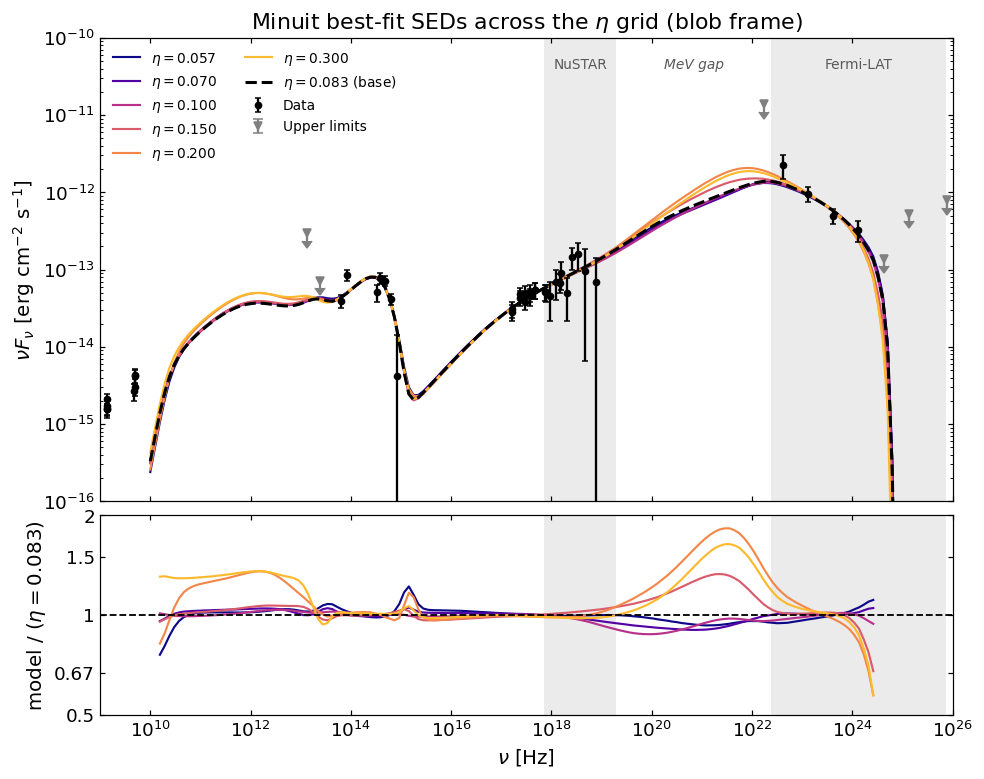

In [3]:
import pandas as pd

# 1. collect the Minuit summaries
rows = []
for eta in eta_grid:
    tag = eta_tag(eta)
    if not os.path.exists(f'summary_Minuit_{tag}.json'):
        print(f"missing: {tag}")
        continue
    with open(f'summary_Minuit_{tag}.json') as f:
        s = json.load(f)
    par = s['params']
    rows.append({
        'eta':          round(s['eta'], 3),
        'chi2':         s['chi2'],
        'dof':          s['dof'],
        'B [G]':        par['B'],
        'Gamma':        par['BulkFactor'],
        'N [cm-3]':     par['N'],
        'gamma_b':      par['gamma_break'],
        'p_1':          par['p_1'],
        'M_BH [Msun]':  par['M_BH'],
        'L_Disk':       par['L_Disk'],
        'L_Disk/eta':   par['L_Disk'] / s['eta'],        # = Mdot c^2 : same disc if ~constant
        'R_H [cm]':     par['R_H'],
        'R_H/R_BLR':    par['R_H'] / s['R_BLR_out'],     # > 1 : blob outside the BLR
        'R_H/R_DT':     par['R_H'] / s['R_DT'],          # < 1 : blob inside the torus
        'T_DT [K]':     par['T_DT'],
        'R_in [Rs]':    par['R_inner_Sw'],
        'R_out [Rs]':   par['R_ext_Sw'],
        'at bound':     ', '.join(s['at_bound']) or '-',
    })

grid_table = pd.DataFrame(rows)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3g}')
print(grid_table.to_string(index=False))
grid_table.to_csv('eta_grid_minuit_summary.csv', index=False)

# Spread of chi2 across the grid: tells whether the data prefer any eta
print(f"\nchi2 range across the grid: {grid_table['chi2'].min():.2f} - {grid_table['chi2'].max():.2f}"
      f"  (Delta chi2 = {grid_table['chi2'].max() - grid_table['chi2'].min():.2f})")
# 2. overlay of the Minuit SEDs + ratio to the eta = 0.083 model
NU_PLOT_MIN, NU_PLOT_MAX = 1e9, 1e26     # x-range of both panels
NU_RATIO_MAX = 3e24                      # above this all models are in the cutoff -> ratio meaningless
F_RATIO_MIN  = 1e-15                     # ignore the ratio where the reference flux is below this

# observed bands (Hz): 1 keV = 2.418e17 Hz
bands = {'NuSTAR':    (3 * 2.418e17,  79 * 2.418e17),
         'Fermi-LAT': (0.1 * 2.418e23, 300 * 2.418e23)}

# discrete, well separated colours; the reference model is drawn separately in black
colors = plt.cm.plasma(np.linspace(0.0, 0.85, len(eta_grid)))

fig, (ax, axr) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1.3], 'hspace': 0.04})

# reference model (eta = 1/12)
ref = FitModel.load_model(f'Model_Minuit_{eta_tag(1/12)}.pkl')
ref.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
ref.jet_leptonic.eval()
ref.eval()
nu_ref, f_ref = ref.SED.nu.value, ref.SED.nuFnu.value

# where the ratio is meaningful
ok_ref = (nu_ref >= NU_FIT_MIN) & (nu_ref <= NU_RATIO_MAX) & (f_ref > F_RATIO_MIN)

ratio_max = 1.0
for eta, col in zip(eta_grid, colors):
    tag = eta_tag(eta)
    if np.isclose(eta, 1/12):
        continue                                   # reference drawn below
    if not os.path.exists(f'Model_Minuit_{tag}.pkl'):
        continue
    m = FitModel.load_model(f'Model_Minuit_{tag}.pkl')
    m.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
    m.jet_leptonic.eval()
    m.eval()
    nu_m, f_m = m.SED.nu.value, m.SED.nuFnu.value

    # top panel: SED
    ax.loglog(nu_m, f_m, color=col, lw=1.4, label=rf'$\eta = {eta:.3f}$')

    # bottom panel: ratio on the reference frequency grid
    f_on_ref = 10**np.interp(np.log10(nu_ref), np.log10(nu_m), np.log10(np.clip(f_m, 1e-40, None)))
    r = f_on_ref[ok_ref] / f_ref[ok_ref]
    axr.plot(nu_ref[ok_ref], r, color=col, lw=1.4)
    ratio_max = max(ratio_max, r.max(), 1 / r.min())

# reference on top of everything
ax.loglog(nu_ref, f_ref, color='k', lw=2.0, ls='--', label=r'$\eta = 0.083$ (base)', zorder=5)
axr.axhline(1, color='k', ls='--', lw=1.2)

# data
nu_d  = np.array(sed_data.table['nu_data'])
fl_d  = np.array(sed_data.table['nuFnu_data'])
err_d = np.array(sed_data.table['dnuFnu_data'])
ul    = np.array(sed_data.table['UL'], dtype=bool)
ax.errorbar(nu_d[~ul], fl_d[~ul], yerr=err_d[~ul], fmt='o', color='k', ms=4, capsize=2,
            label='Data', zorder=10)
ax.errorbar(nu_d[ul], fl_d[ul], yerr=0.2 * fl_d[ul], uplims=True, fmt='v', color='gray', ms=5,
            label='Upper limits', zorder=10)

# shade the instrument bands in both panels
for name, (lo, hi) in bands.items():
    for a in (ax, axr):
        a.axvspan(lo, hi, color='0.85', alpha=0.5, zorder=0, lw=0)
    ax.text(np.sqrt(lo * hi), 4e-11, name, ha='center', fontsize=9, color='0.35')
# the gap between the two instruments
ax.text(np.sqrt(bands['NuSTAR'][1] * bands['Fermi-LAT'][0]), 4e-11, 'MeV gap',
        ha='center', fontsize=9, color='0.35', style='italic')

ax.set_ylim(1e-16, 1e-10)
ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]')
ax.set_title(r'Minuit best-fit SEDs across the $\eta$ grid (blob frame)')
ax.legend(fontsize=9, ncol=2, loc='upper left', frameon=False)

# ratio panel: log y-axis so that x2 and x0.5 look symmetric
lim = min(3.0, 1.1 * ratio_max)
axr.set_yscale('log')
axr.set_ylim(1 / lim, lim)
ticks = [t for t in [0.5, 0.67, 1, 1.5, 2, 3] if 1 / lim <= t <= lim]
axr.set_yticks(ticks)
axr.set_yticklabels([f'{t:g}' for t in ticks])
axr.minorticks_off()
axr.set_xscale('log')
axr.set_xlim(NU_PLOT_MIN, NU_PLOT_MAX)
axr.set_xlabel(r'$\nu$ [Hz]')
axr.set_ylabel(r'model / ($\eta = 0.083$)')

plt.savefig(os.path.join(FIG_DIR, 'SED_Minuit_eta_overlay.png'), dpi=200, bbox_inches='tight')
plt.show()

## Which process makes the X-rays, MeV and GeV emission at each η?

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in

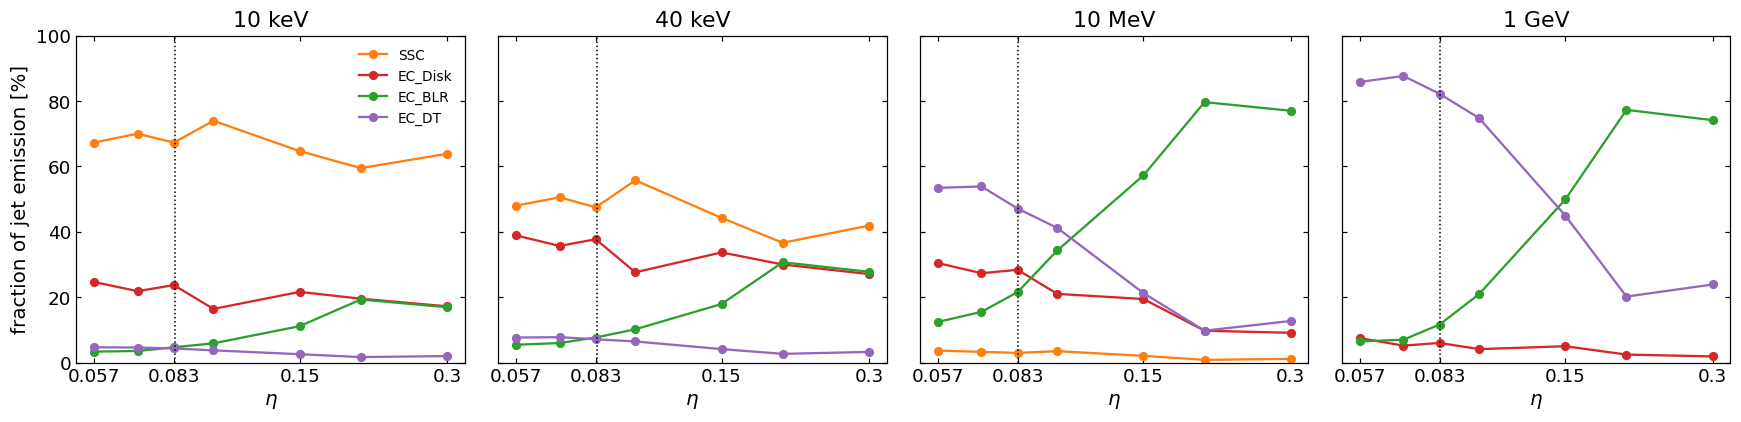

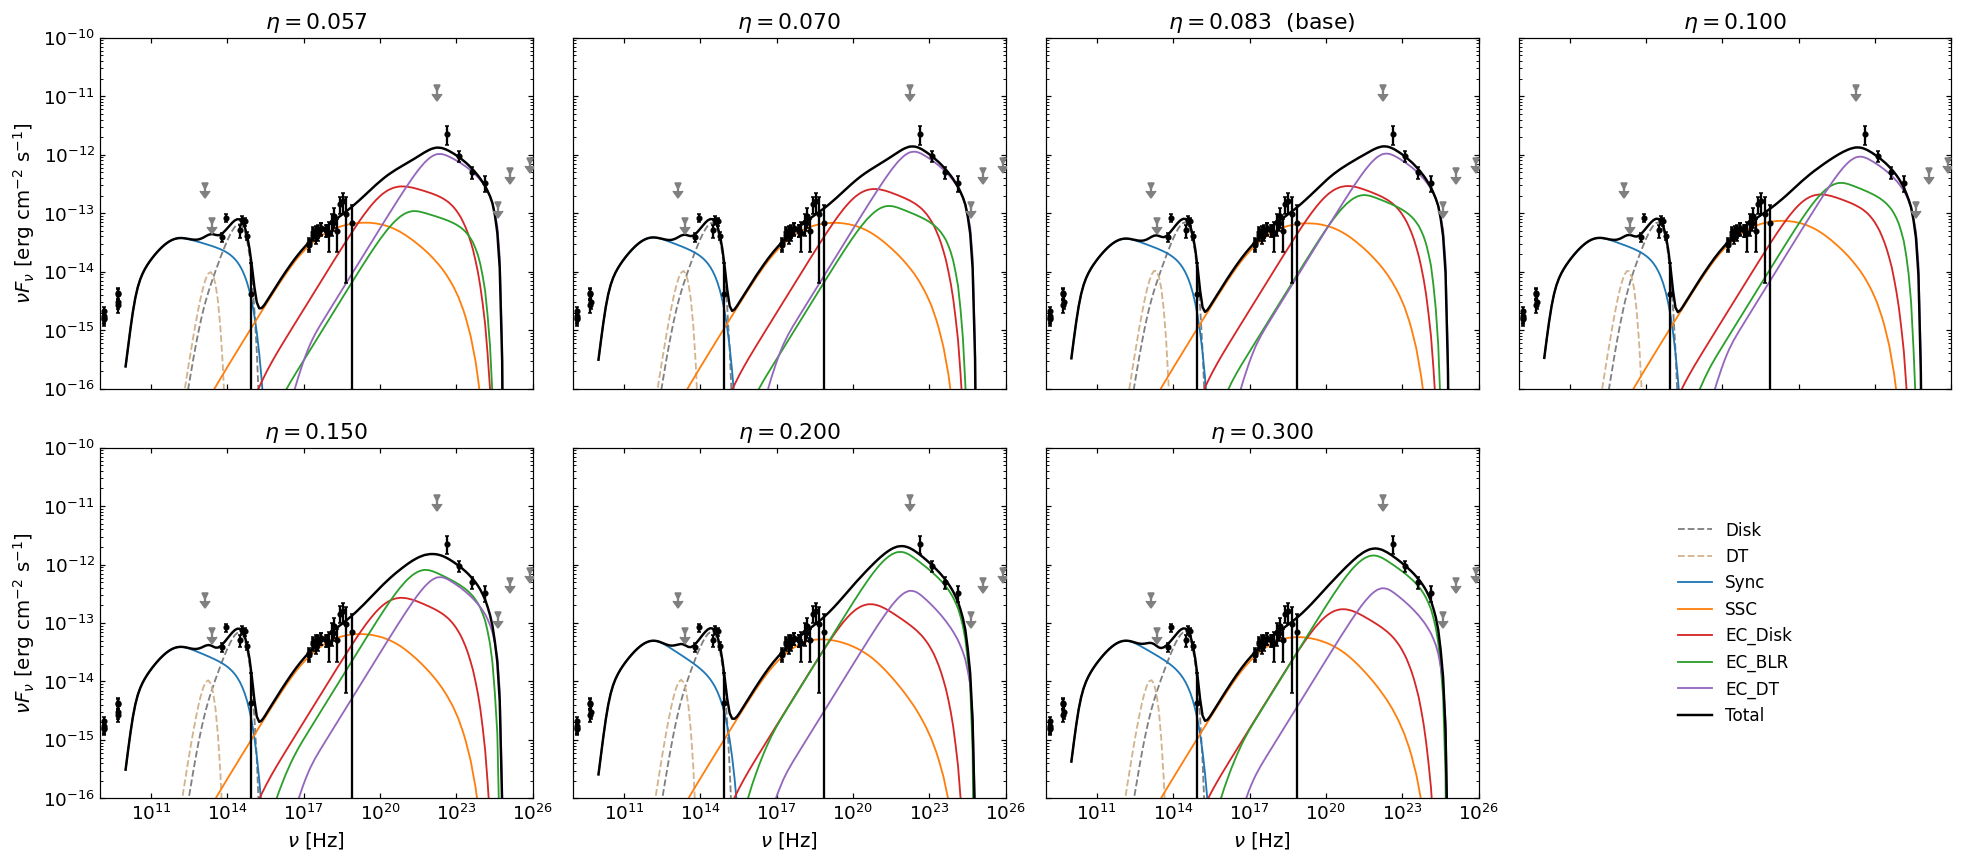

In [4]:
keV_to_Hz = 2.418e17
nu_check = {'10 keV':  10 * keV_to_Hz,
            '40 keV':  40 * keV_to_Hz,
            '10 MeV':  1e4 * keV_to_Hz,
            '1 GeV':   1e6 * keV_to_Hz}

jet_comps   = ['Sync', 'SSC', 'EC_Disk', 'EC_BLR', 'EC_DT']   # non-thermal jet emission
therm_comps = ['Disk', 'DT']                                  # thermal external fields (plot only)
comp_colors = {'Sync': 'tab:blue', 'SSC': 'tab:orange', 'EC_Disk': 'tab:red',
               'EC_BLR': 'tab:green', 'EC_DT': 'tab:purple',
               'Disk': 'gray', 'DT': 'tan'}

def get_comp_sed(fit_model, name):
    """Return (nu, nuFnu) of a jet component, or None if it does not exist / is empty.
    jet.eval() must have been called before."""
    try:
        c = fit_model.jet_leptonic.get_spectral_component_by_name(name)
    except Exception:
        return None
    if c is None or c.SED.nu is None:
        return None
    return c.SED.nu.value, c.SED.nuFnu.value

def flux_at(nu, f, nu0):
    """log-log interpolation of nuFnu at nu0"""
    return 10**np.interp(np.log10(nu0), np.log10(nu), np.log10(np.clip(f, 1e-60, None)))

# 2. loop over the grid, store component SEDs and fractions
comp_seds = {}     # comp_seds[eta][comp] = (nu, nuFnu), reused for the figures
frac_rows = []

for eta in eta_grid:
    tag = eta_tag(eta)
    if not os.path.exists(f'Model_Minuit_{tag}.pkl'):
        print(f"missing: {tag}")
        continue

    m = FitModel.load_model(f'Model_Minuit_{tag}.pkl')
    m.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
    m.jet_leptonic.eval()
    m.eval()

    comp_seds[eta] = {}
    comp_seds[eta]['Total'] = (m.SED.nu.value, m.SED.nuFnu.value)    # includes EBL absorption
    for comp in jet_comps + therm_comps:
        s = get_comp_sed(m, comp)
        if s is not None:
            comp_seds[eta][comp] = s

    for band, nu0 in nu_check.items():
        fl = {c: flux_at(*comp_seds[eta][c], nu0) for c in jet_comps if c in comp_seds[eta]}
        tot = sum(fl.values())
        row = {'eta': round(eta, 3), 'band': band, 'nuFnu_tot': tot}
        for c in jet_comps:
            row[c] = fl.get(c, 0.0) / tot
        frac_rows.append(row)

frac_table = pd.DataFrame(frac_rows)
frac_table.to_csv('eta_grid_component_fractions.csv', index=False)

# print one block per band, fractions in %
for band in nu_check:
    t = frac_table[frac_table['band'] == band].copy()
    for c in jet_comps:
        t[c] = 100 * t[c]
    print(f"\n--- {band}  (fraction of jet emission, %) ---")
    t['eta'] = t['eta'].map(lambda x: f'{x:.3f}')
    print(t[['eta'] + jet_comps].to_string(index=False, float_format=lambda x: f'{x:.1f}'))

# 3. fractions vs eta, one panel per energy
fig, axes = plt.subplots(1, len(nu_check), figsize=(16, 4), sharey=True)

for ax, band in zip(axes, nu_check):
    t = frac_table[frac_table['band'] == band]
    for c in jet_comps:
        if t[c].max() < 0.01:          # skip components that are always < 1%
            continue
        ax.plot(t['eta'], 100 * t[c], 'o-', color=comp_colors[c], lw=1.5, ms=5, label=c)
    ax.axvline(1/12, color='k', ls=':', lw=1)
    ax.set_xscale('log')
    ax.set_xticks([0.057, 0.083, 0.15, 0.3])
    ax.set_xticklabels(['0.057', '0.083', '0.15', '0.3'])
    ax.minorticks_off()
    ax.set_title(band)
    ax.set_xlabel(r'$\eta$')
    ax.set_ylim(0, 100)

axes[0].set_ylabel('fraction of jet emission [%]')
axes[0].legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eta_grid_component_fractions.png'), dpi=200, bbox_inches='tight')
plt.show()

# 4. component decomposition for every eta (appendix figure)
nu_d  = np.array(sed_data.table['nu_data'])
fl_d  = np.array(sed_data.table['nuFnu_data'])
err_d = np.array(sed_data.table['dnuFnu_data'])
ul    = np.array(sed_data.table['UL'], dtype=bool)

etas_done = list(comp_seds.keys())
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, eta in zip(axes, etas_done):
    for c in therm_comps + jet_comps:
        if c in comp_seds[eta]:
            nu_c, f_c = comp_seds[eta][c]
            ls = '--' if c in therm_comps else '-'
            ax.loglog(nu_c, f_c, ls=ls, lw=1.2, color=comp_colors[c], label=c)
    ax.loglog(*comp_seds[eta]['Total'], color='k', lw=1.6, label='Total')
    ax.errorbar(nu_d[~ul], fl_d[~ul], yerr=err_d[~ul], fmt='o', color='k', ms=3, capsize=1.5, zorder=10)
    ax.errorbar(nu_d[ul], fl_d[ul], yerr=0.2 * fl_d[ul], uplims=True, fmt='v', color='gray', ms=4, zorder=10)
    ax.set_title(rf'$\eta = {eta:.3f}$' + ('  (base)' if np.isclose(eta, 1/12) else ''))
    ax.set_ylim(1e-16, 1e-10)
    ax.set_xlim(1e9, 1e26)

# last panel: legend only
axes[-1].axis('off')
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc='center', fontsize=11, frameon=False)
for ax in axes[4:]:
    ax.set_xlabel(r'$\nu$ [Hz]')
for ax in axes[::4]:
    ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eta_grid_components_all.png'), dpi=200, bbox_inches='tight')
plt.show()

## MCMC for every η

R_H fixed at the Minuit value: 1.065e+18 cm
chain_eta_0p057_7p.npz exists -> sampling skipped

Acceptance fraction: 0.351   (healthy: 0.2-0.5)
   tau(          B) =   49.0 steps   ->   10.2 autocorrelation times
   tau( BulkFactor) =   46.2 steps   ->   10.8 autocorrelation times
   tau(          N) =   43.6 steps   ->   11.5 autocorrelation times
   tau(gamma_break) =   48.7 steps   ->   10.3 autocorrelation times
   tau(        p_1) =   45.0 steps   ->   11.1 autocorrelation times
   tau(       M_BH) =   44.9 steps   ->   11.1 autocorrelation times
   tau(     L_Disk) =   50.4 steps   ->    9.9 autocorrelation times

=== MCMC posterior (eta = 0.057, 7 parameters) ===
  Parameter    Minuit    Median -1 sigma +1 sigma
          B 7.130e-02 7.997e-02 1.93e-02 2.18e-02
 BulkFactor 1.771e+01 2.054e+01 5.44e+00 5.75e+00
          N 2.095e+03 1.872e+03 2.89e+02 4.30e+02
gamma_break 7.514e+02 8.329e+02 2.04e+02 3.45e+02
        p_1 3.242e+00 3.432e+00 2.10e-01 2.39e-01
       M_BH 1.740e+09 

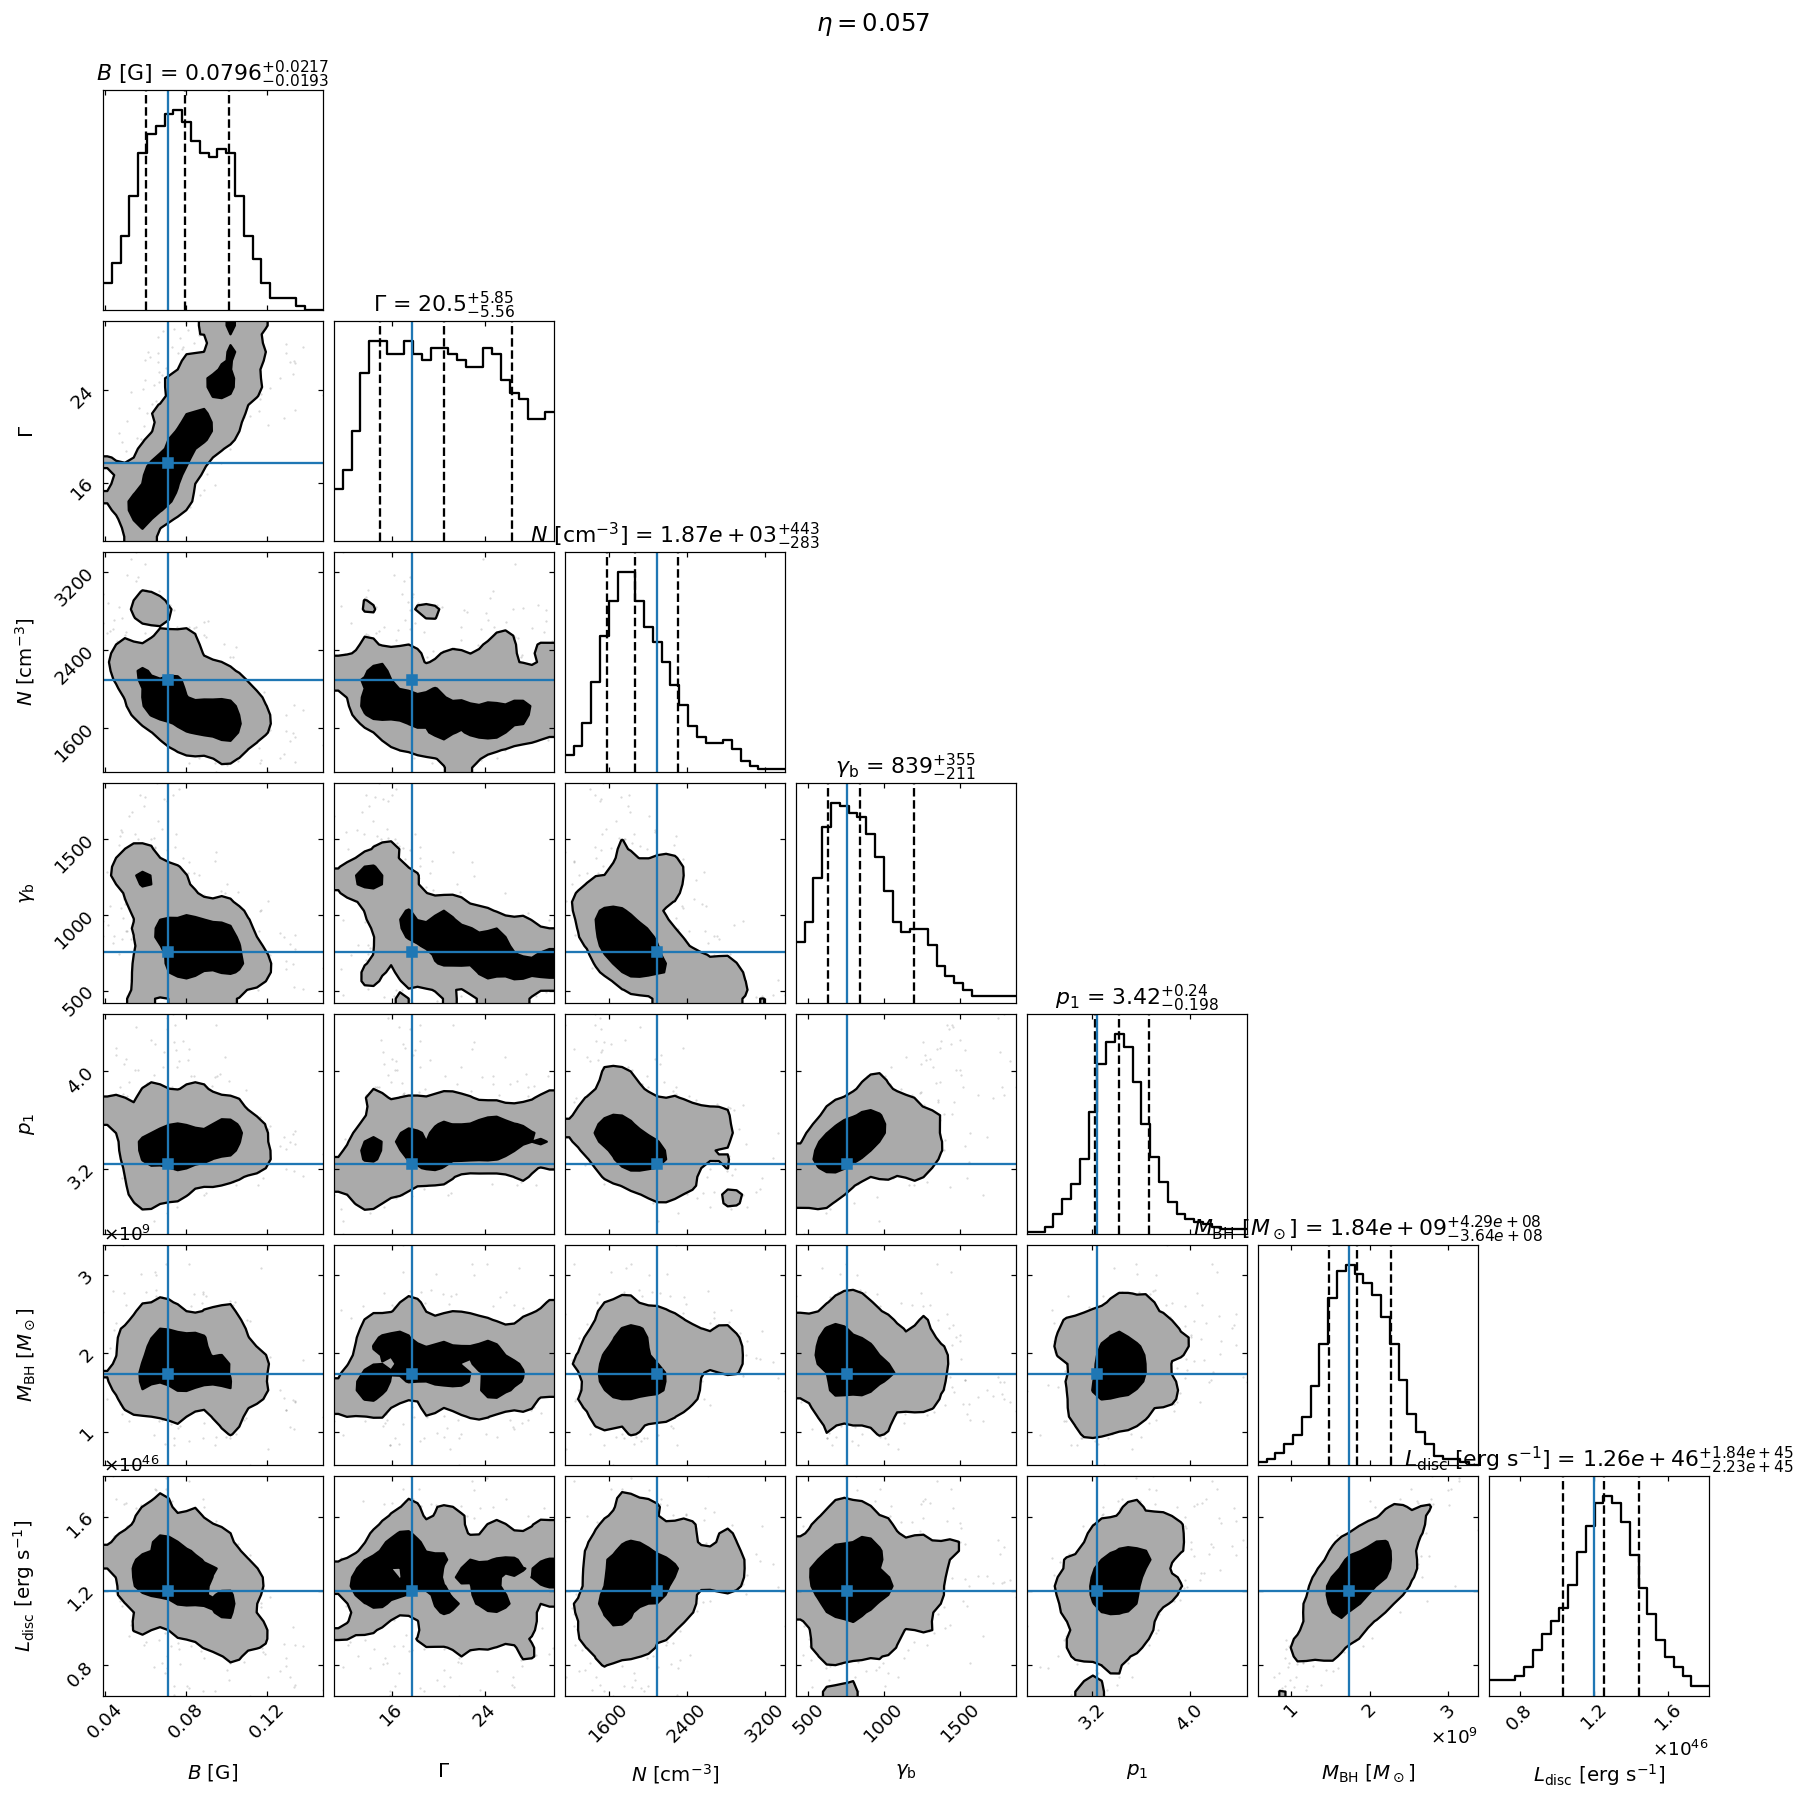


N-B correlation: -0.54
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8

chi2 of the median SED (detections in the fit range): 26.6 for 32 points


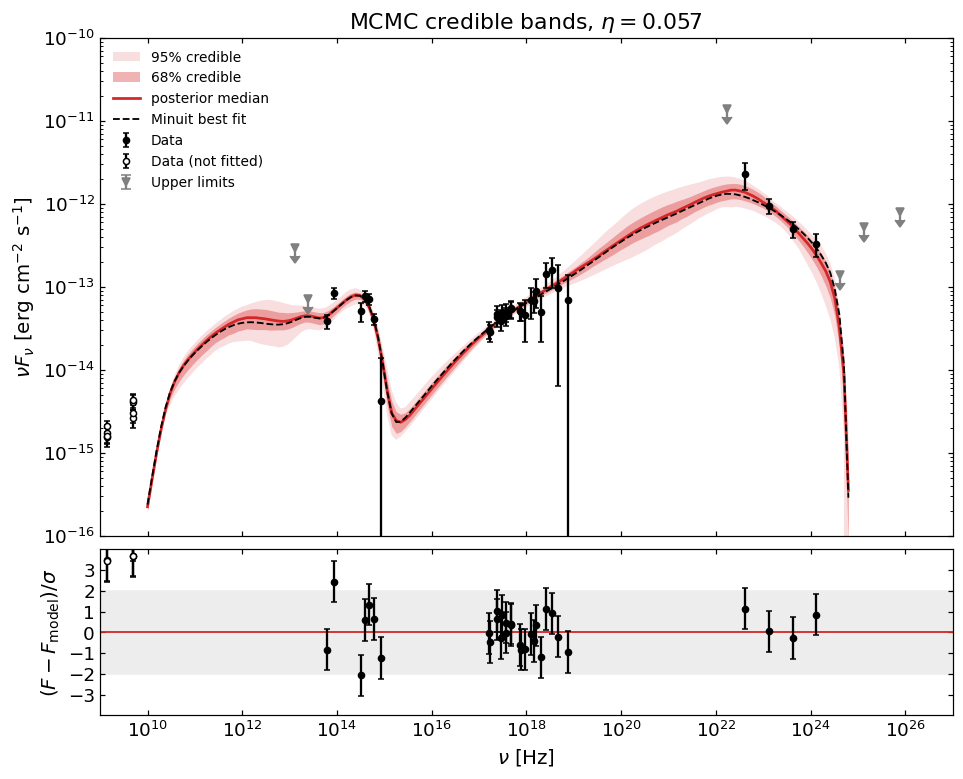

R_H fixed at the Minuit value: 1.180e+18 cm
chain_eta_0p070_7p.npz exists -> sampling skipped

Acceptance fraction: 0.342   (healthy: 0.2-0.5)
   tau(          B) =   45.7 steps   ->   11.0 autocorrelation times
   tau( BulkFactor) =   45.9 steps   ->   10.9 autocorrelation times
   tau(          N) =   47.1 steps   ->   10.6 autocorrelation times
   tau(gamma_break) =   44.8 steps   ->   11.2 autocorrelation times
   tau(        p_1) =   42.3 steps   ->   11.8 autocorrelation times
   tau(       M_BH) =   45.9 steps   ->   10.9 autocorrelation times
   tau(     L_Disk) =   44.9 steps   ->   11.1 autocorrelation times

=== MCMC posterior (eta = 0.070, 7 parameters) ===
  Parameter    Minuit    Median -1 sigma +1 sigma
          B 6.325e-02 7.510e-02 2.07e-02 2.43e-02
 BulkFactor 1.803e+01 2.148e+01 5.12e+00 6.18e+00
          N 1.797e+03 1.637e+03 3.38e+02 4.90e+02
gamma_break 8.300e+02 8.710e+02 2.37e+02 2.47e+02
        p_1 3.318e+00 3.450e+00 2.00e-01 2.33e-01
       M_BH 1.782e+09 

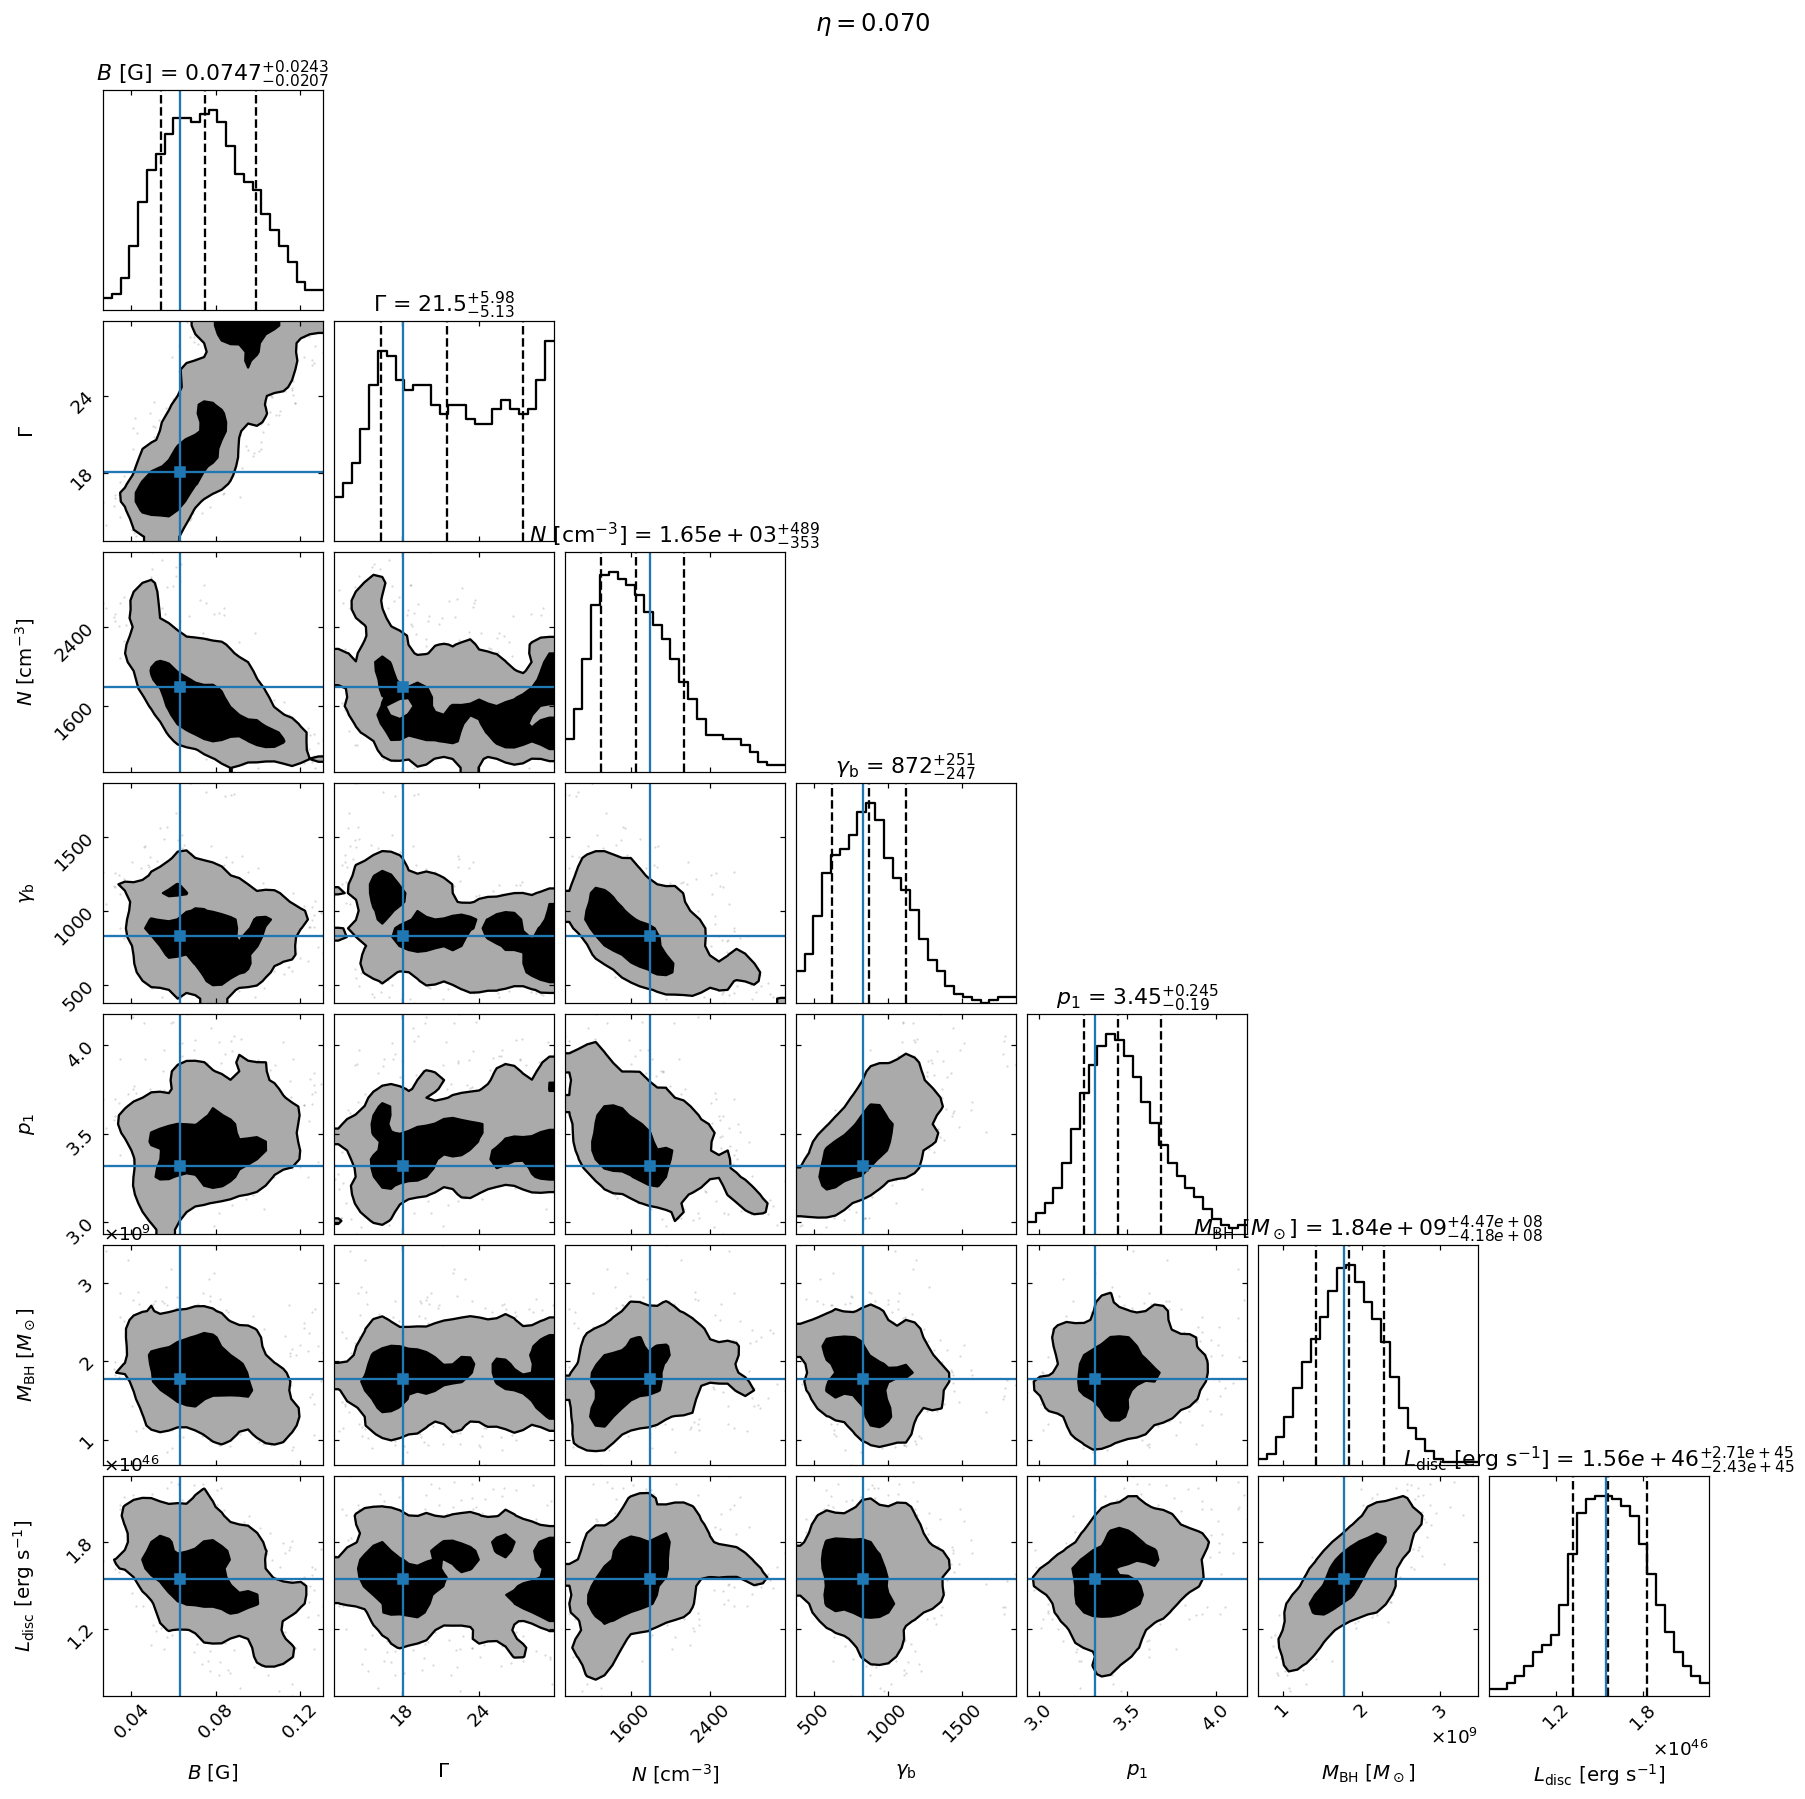


N-B correlation: -0.64
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8

chi2 of the median SED (detections in the fit range): 25.7 for 32 points


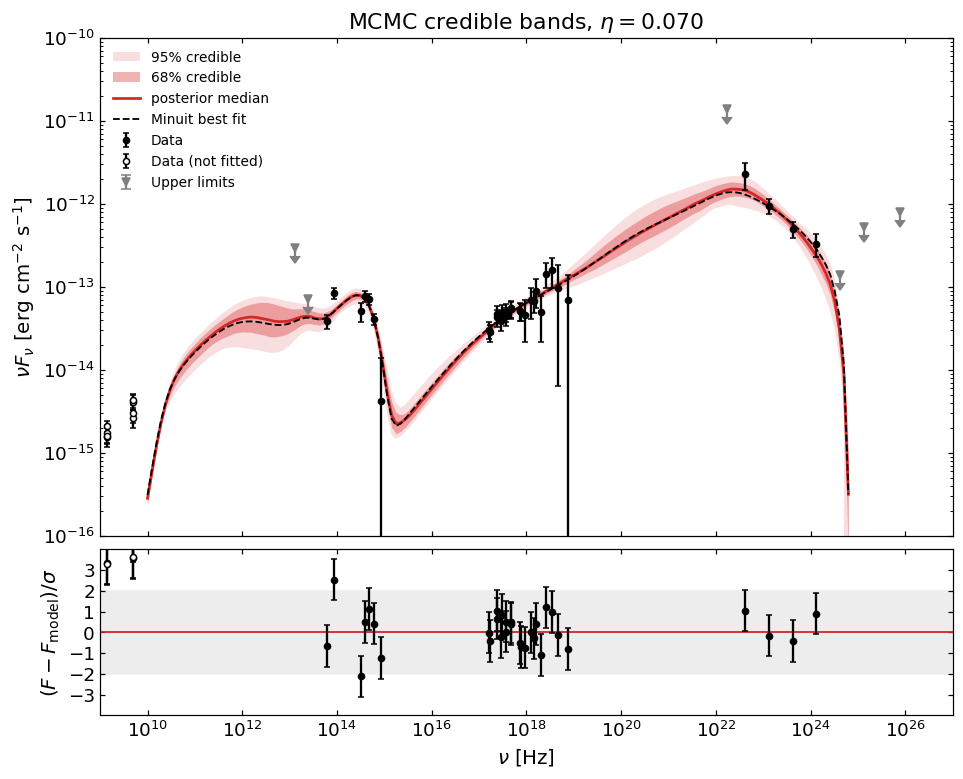

R_H fixed at the Minuit value: 1.200e+18 cm
chain_eta_0p083_7p.npz exists -> sampling skipped

Acceptance fraction: 0.300   (healthy: 0.2-0.5)
   tau(          B) =   49.5 steps   ->   10.1 autocorrelation times
   tau( BulkFactor) =   50.4 steps   ->    9.9 autocorrelation times
   tau(          N) =   49.7 steps   ->   10.1 autocorrelation times
   tau(gamma_break) =   47.6 steps   ->   10.5 autocorrelation times
   tau(        p_1) =   45.5 steps   ->   11.0 autocorrelation times
   tau(       M_BH) =   43.2 steps   ->   11.6 autocorrelation times
   tau(     L_Disk) =   42.8 steps   ->   11.7 autocorrelation times

=== MCMC posterior (eta = 0.083, 7 parameters) ===
  Parameter    Minuit    Median -1 sigma +1 sigma
          B 6.013e-02 5.905e-02 1.57e-02 2.53e-02
 BulkFactor 1.836e+01 1.791e+01 4.23e+00 6.50e+00
          N 1.771e+03 1.834e+03 5.03e+02 6.21e+02
gamma_break 8.375e+02 9.346e+02 2.95e+02 2.98e+02
        p_1 3.309e+00 3.382e+00 3.01e-01 2.95e-01
       M_BH 1.809e+09 

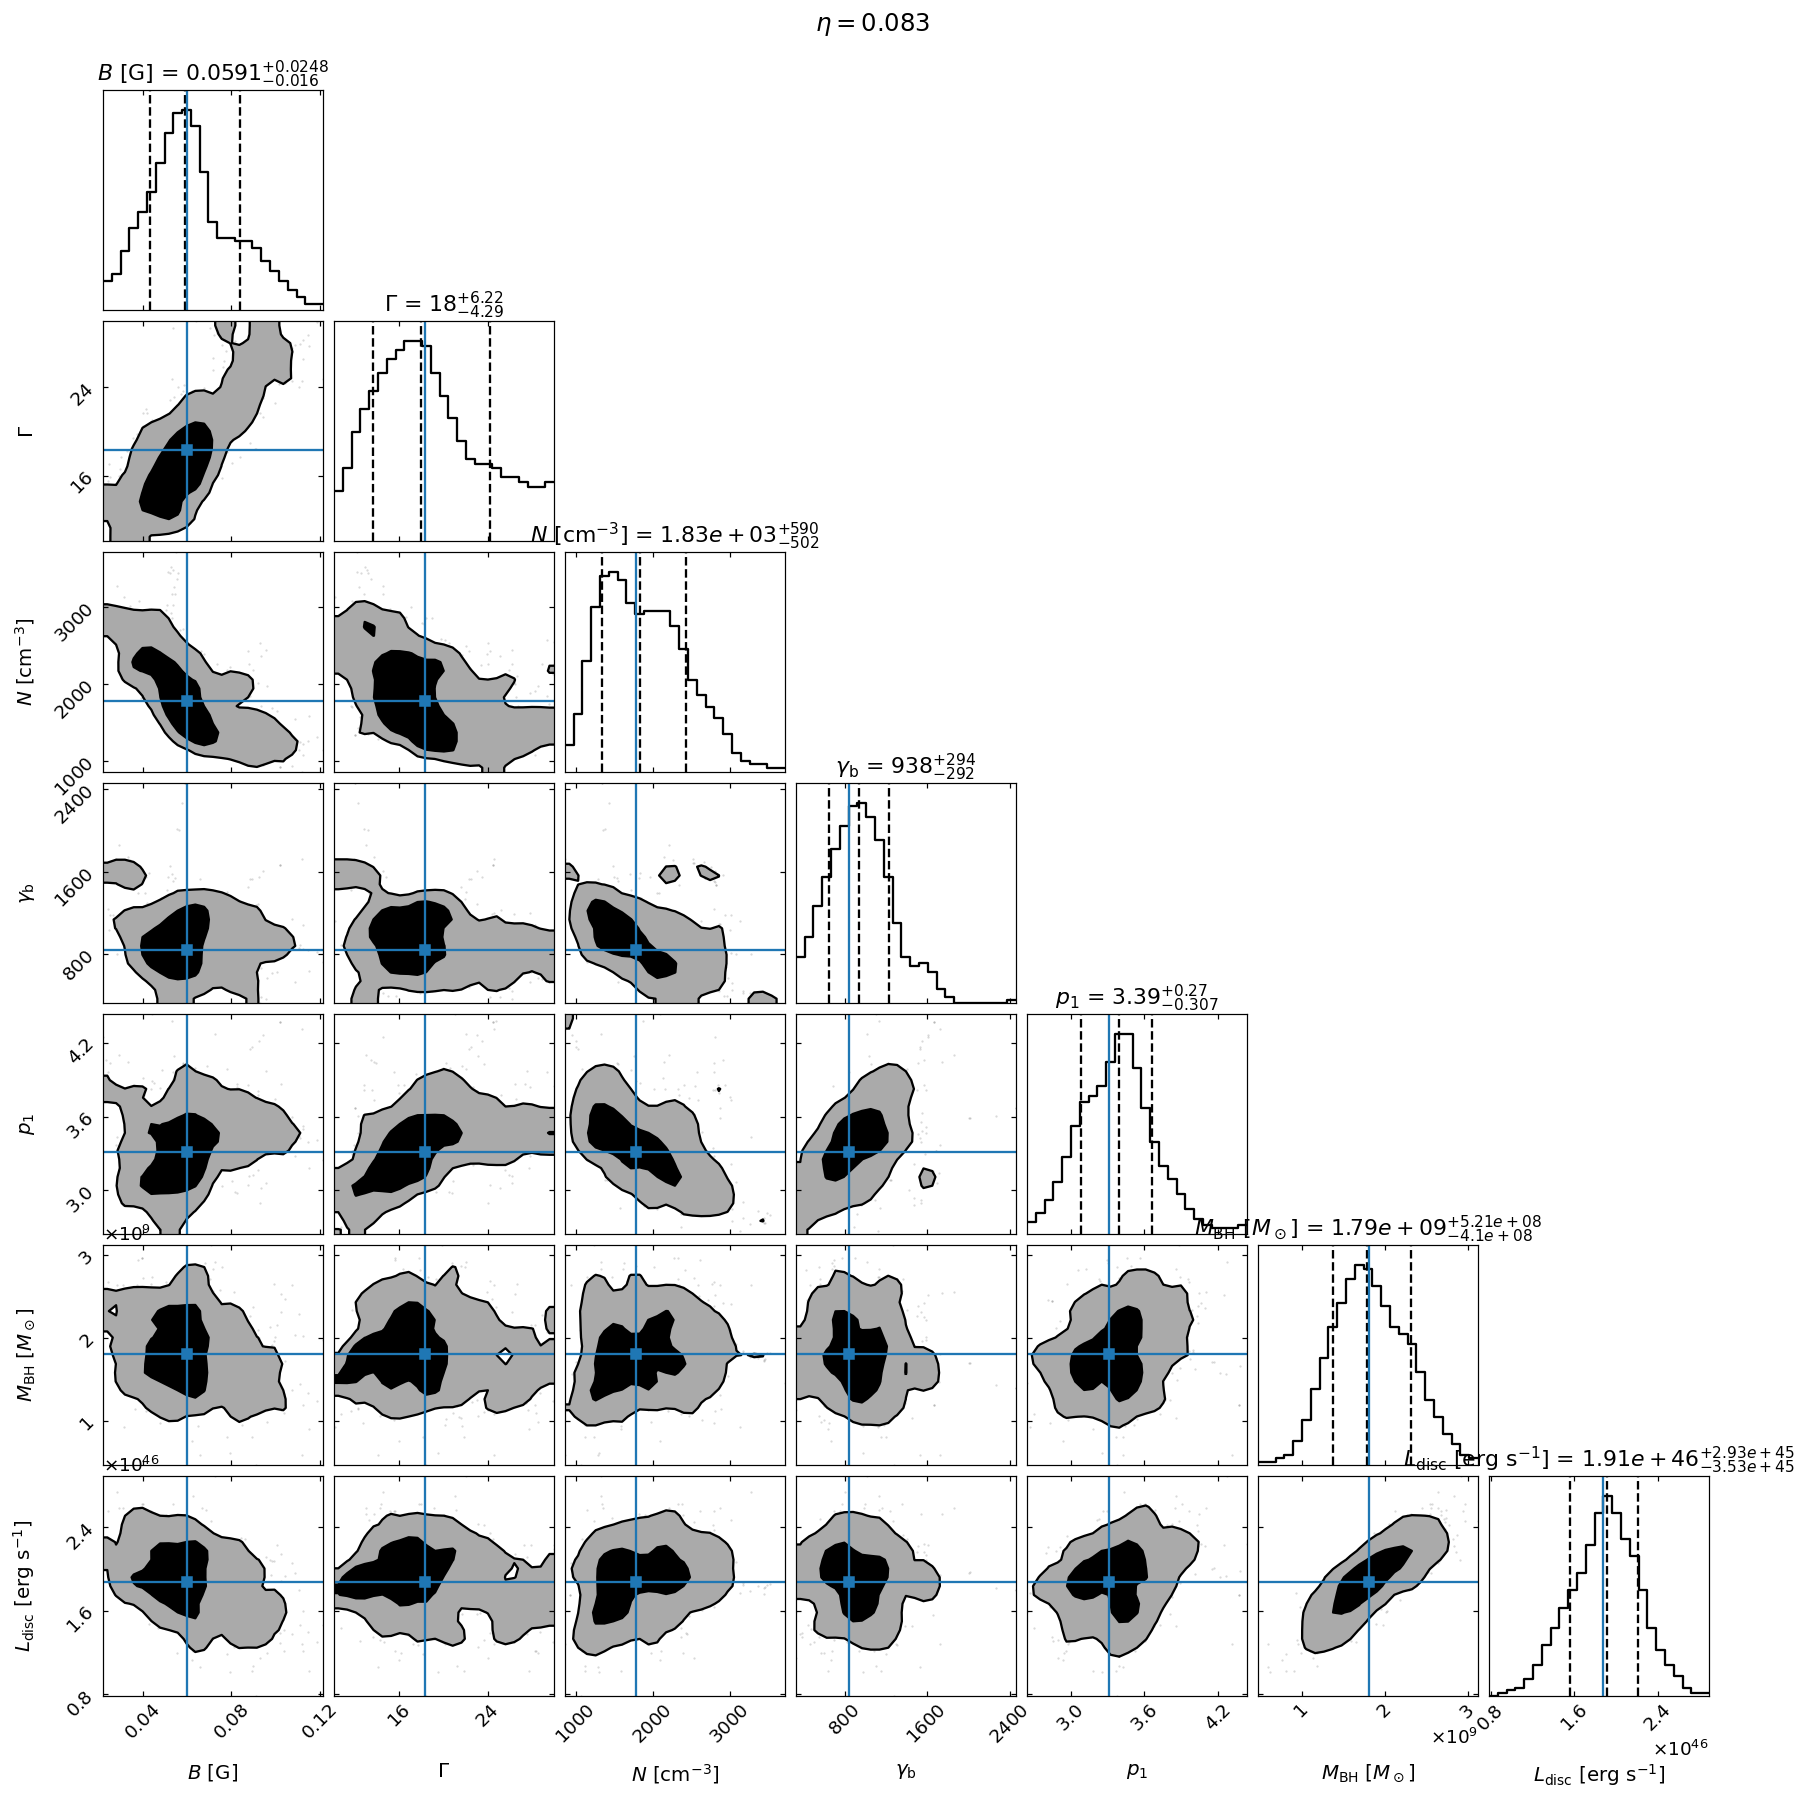


N-B correlation: -0.68
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8

chi2 of the median SED (detections in the fit range): 26.8 for 32 points


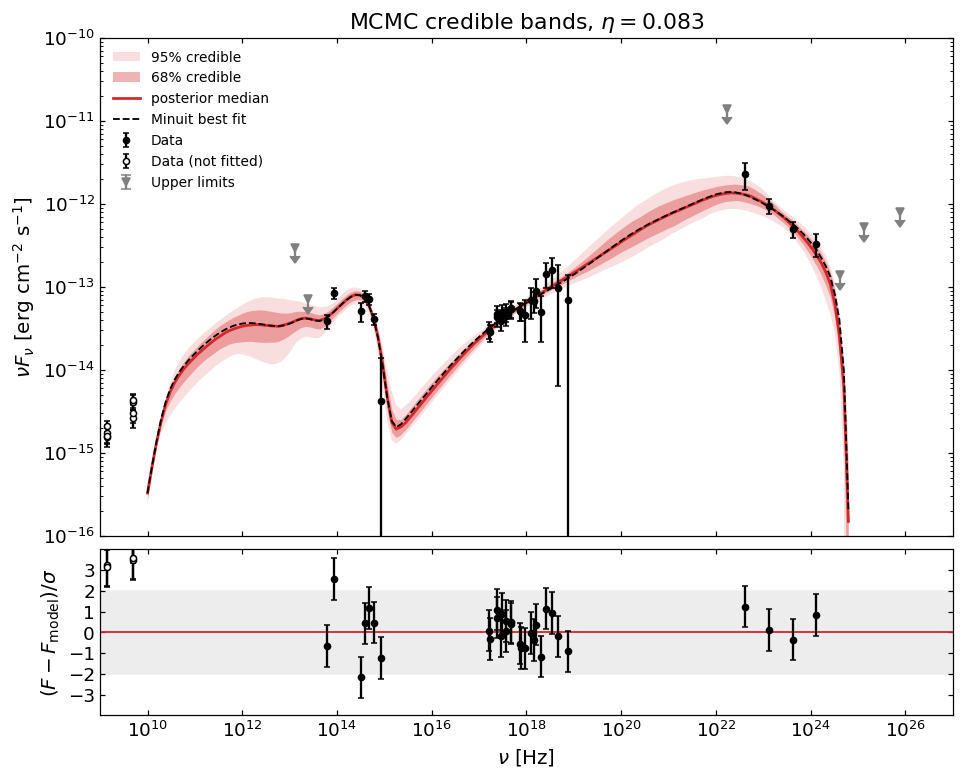

R_H fixed at the Minuit value: 1.202e+18 cm
chain_eta_0p100_7p.npz exists -> sampling skipped

Acceptance fraction: 0.359   (healthy: 0.2-0.5)
   tau(          B) =   48.9 steps   ->   10.2 autocorrelation times
   tau( BulkFactor) =   47.0 steps   ->   10.6 autocorrelation times
   tau(          N) =   37.5 steps   ->   13.3 autocorrelation times
   tau(gamma_break) =   39.6 steps   ->   12.6 autocorrelation times
   tau(        p_1) =   38.9 steps   ->   12.8 autocorrelation times
   tau(       M_BH) =   40.6 steps   ->   12.3 autocorrelation times
   tau(     L_Disk) =   42.6 steps   ->   11.7 autocorrelation times

=== MCMC posterior (eta = 0.100, 7 parameters) ===
  Parameter    Minuit    Median -1 sigma +1 sigma
          B 5.893e-02 7.476e-02 1.82e-02 1.87e-02
 BulkFactor 1.839e+01 2.329e+01 5.18e+00 4.38e+00
          N 1.778e+03 1.586e+03 3.05e+02 4.53e+02
gamma_break 8.700e+02 8.984e+02 2.42e+02 2.58e+02
        p_1 3.299e+00 3.449e+00 2.27e-01 2.81e-01
       M_BH 1.814e+09 

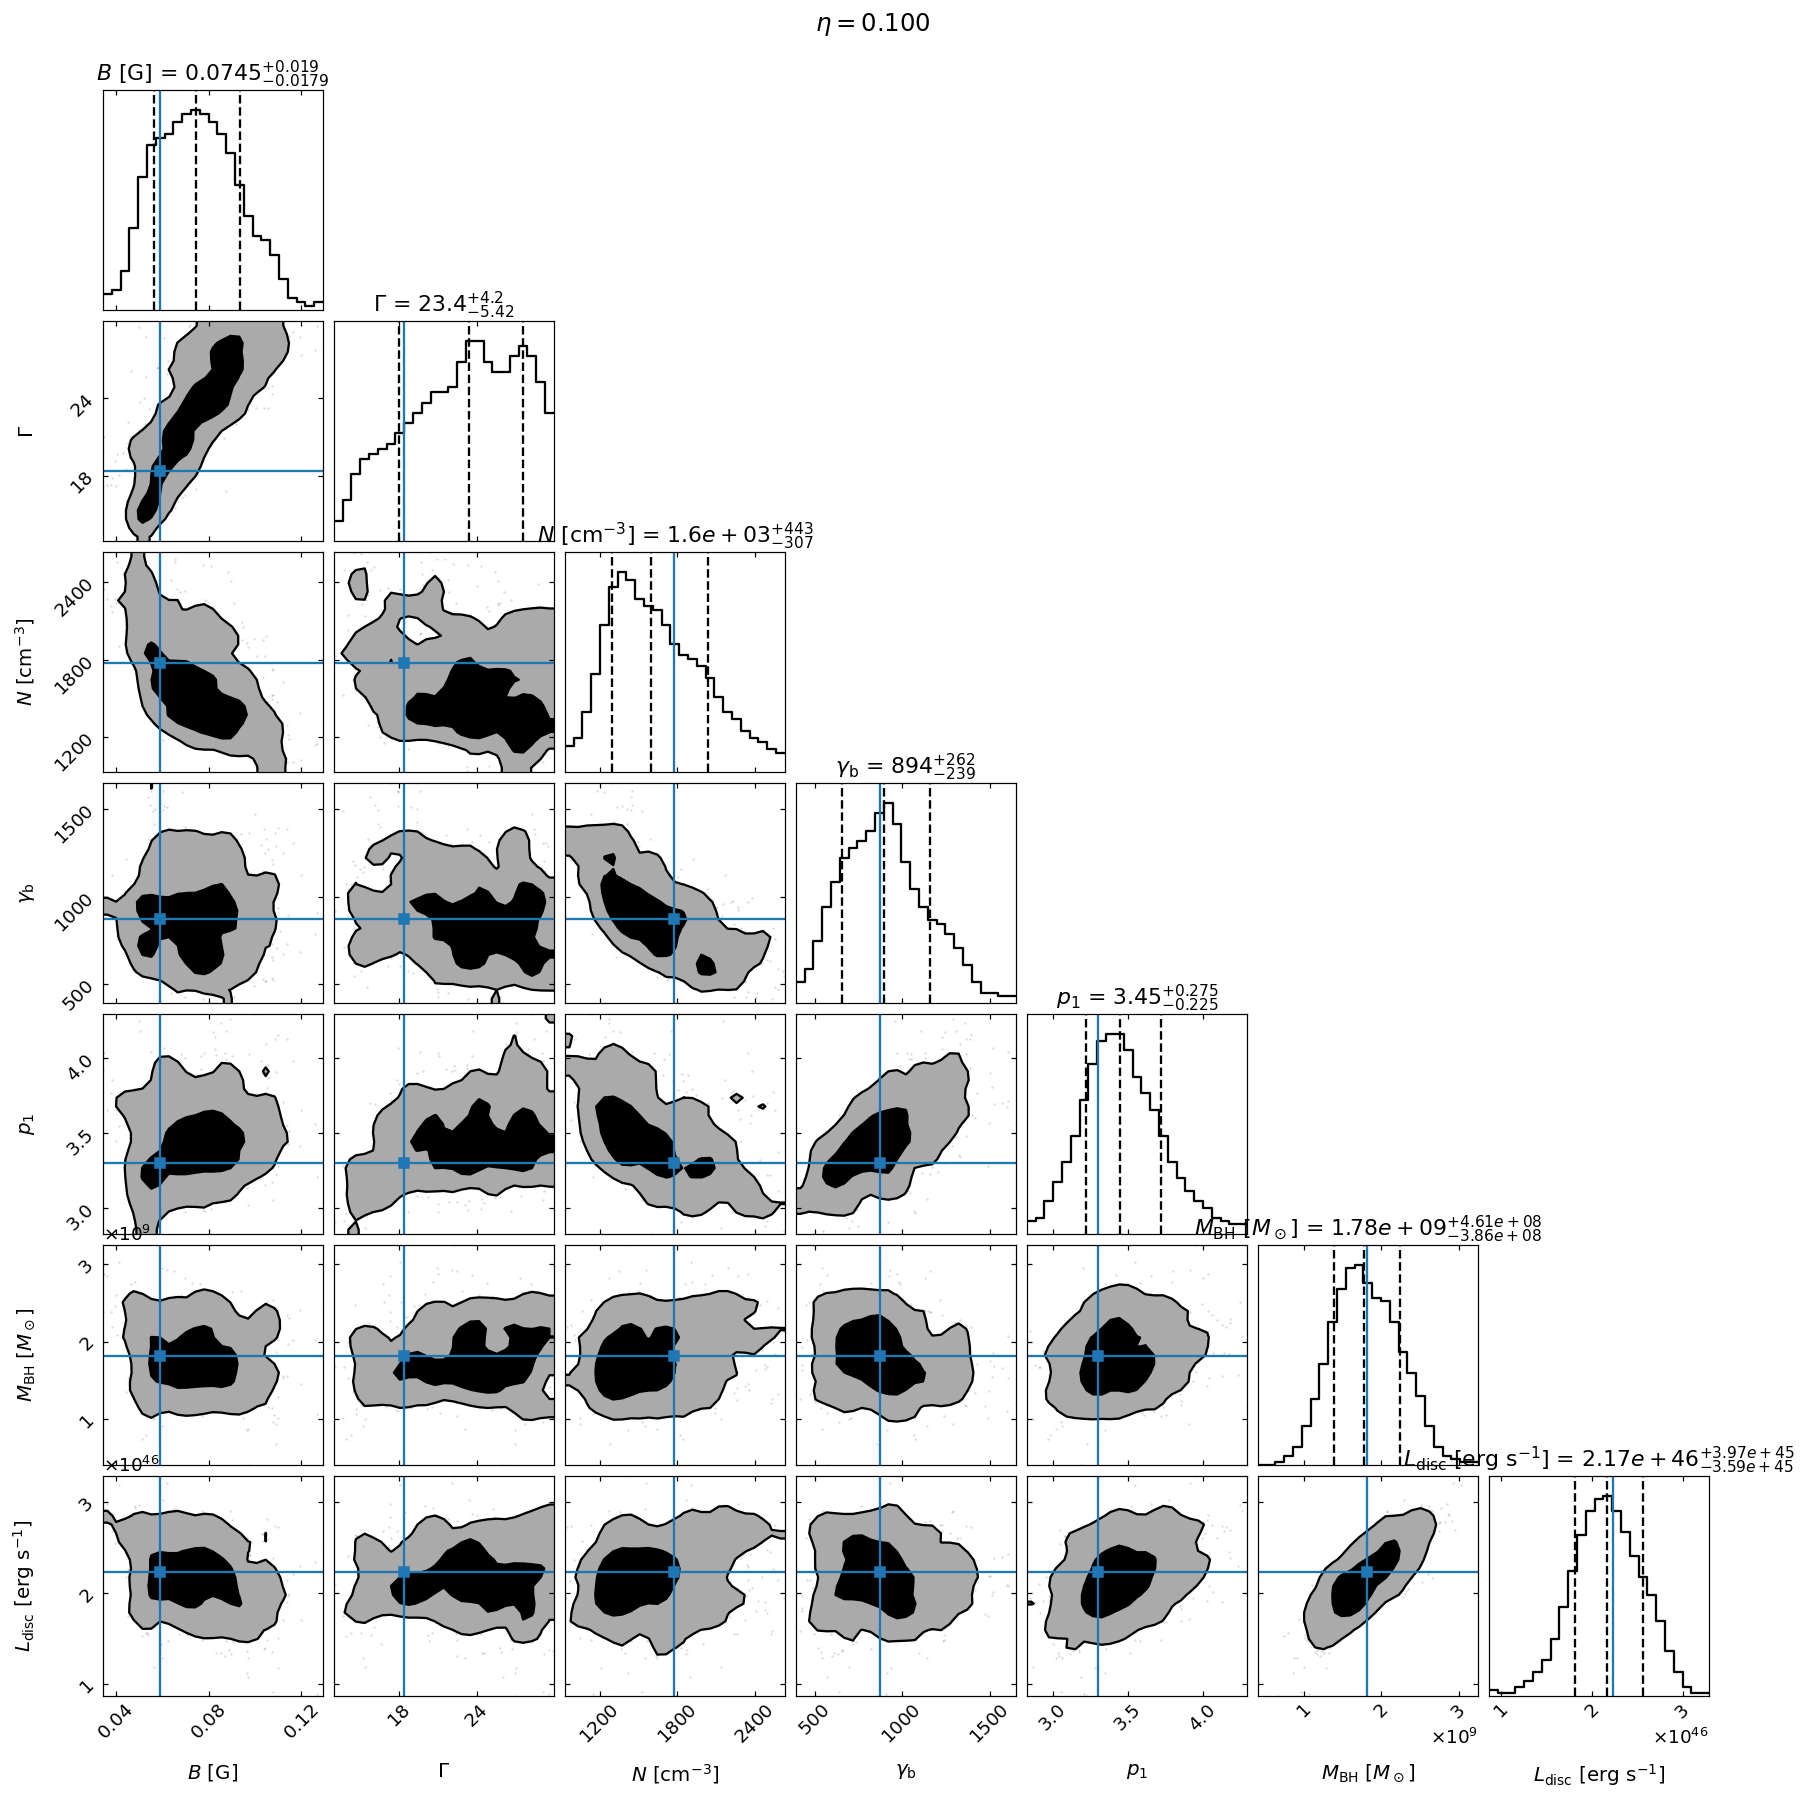


N-B correlation: -0.59
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8

chi2 of the median SED (detections in the fit range): 25.8 for 32 points


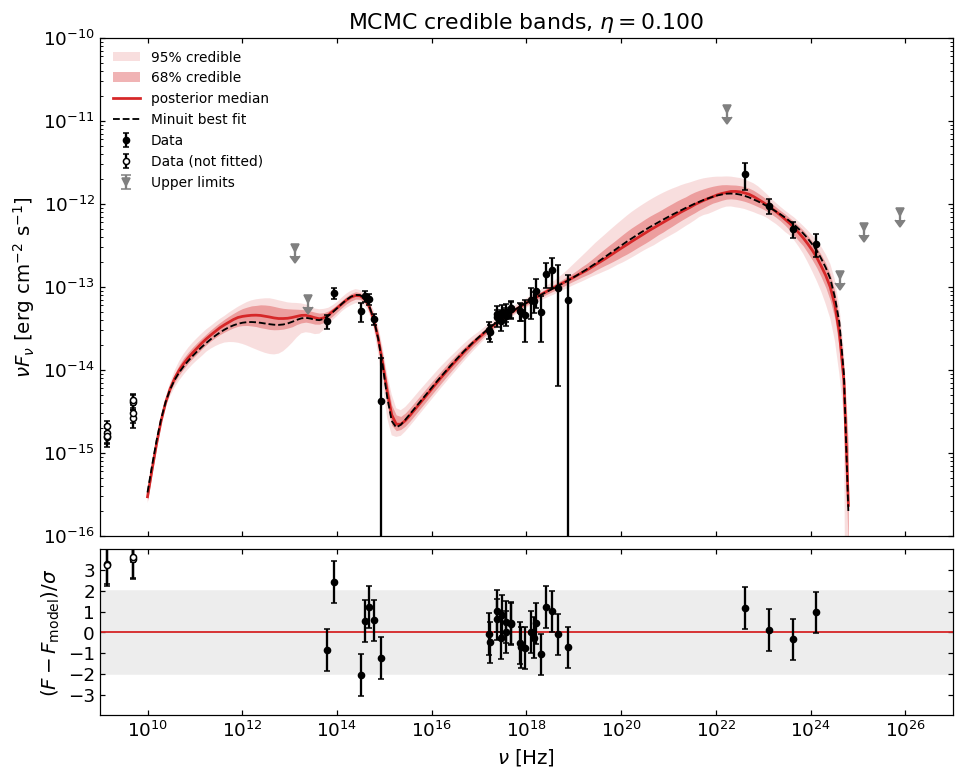

R_H fixed at the Minuit value: 1.183e+18 cm
chain_eta_0p150_7p.npz exists -> sampling skipped

Acceptance fraction: 0.341   (healthy: 0.2-0.5)
   tau(          B) =   44.6 steps   ->   11.2 autocorrelation times
   tau( BulkFactor) =   43.0 steps   ->   11.6 autocorrelation times
   tau(          N) =   47.6 steps   ->   10.5 autocorrelation times
   tau(gamma_break) =   45.0 steps   ->   11.1 autocorrelation times
   tau(        p_1) =   44.6 steps   ->   11.2 autocorrelation times
   tau(       M_BH) =   43.1 steps   ->   11.6 autocorrelation times
   tau(     L_Disk) =   43.4 steps   ->   11.5 autocorrelation times

=== MCMC posterior (eta = 0.150, 7 parameters) ===
  Parameter    Minuit    Median -1 sigma +1 sigma
          B 6.474e-02 7.288e-02 1.71e-02 2.19e-02
 BulkFactor 1.953e+01 2.231e+01 5.12e+00 4.95e+00
          N 1.688e+03 1.645e+03 3.76e+02 4.44e+02
gamma_break 8.499e+02 8.510e+02 2.13e+02 3.30e+02
        p_1 3.352e+00 3.427e+00 2.65e-01 3.07e-01
       M_BH 1.705e+09 

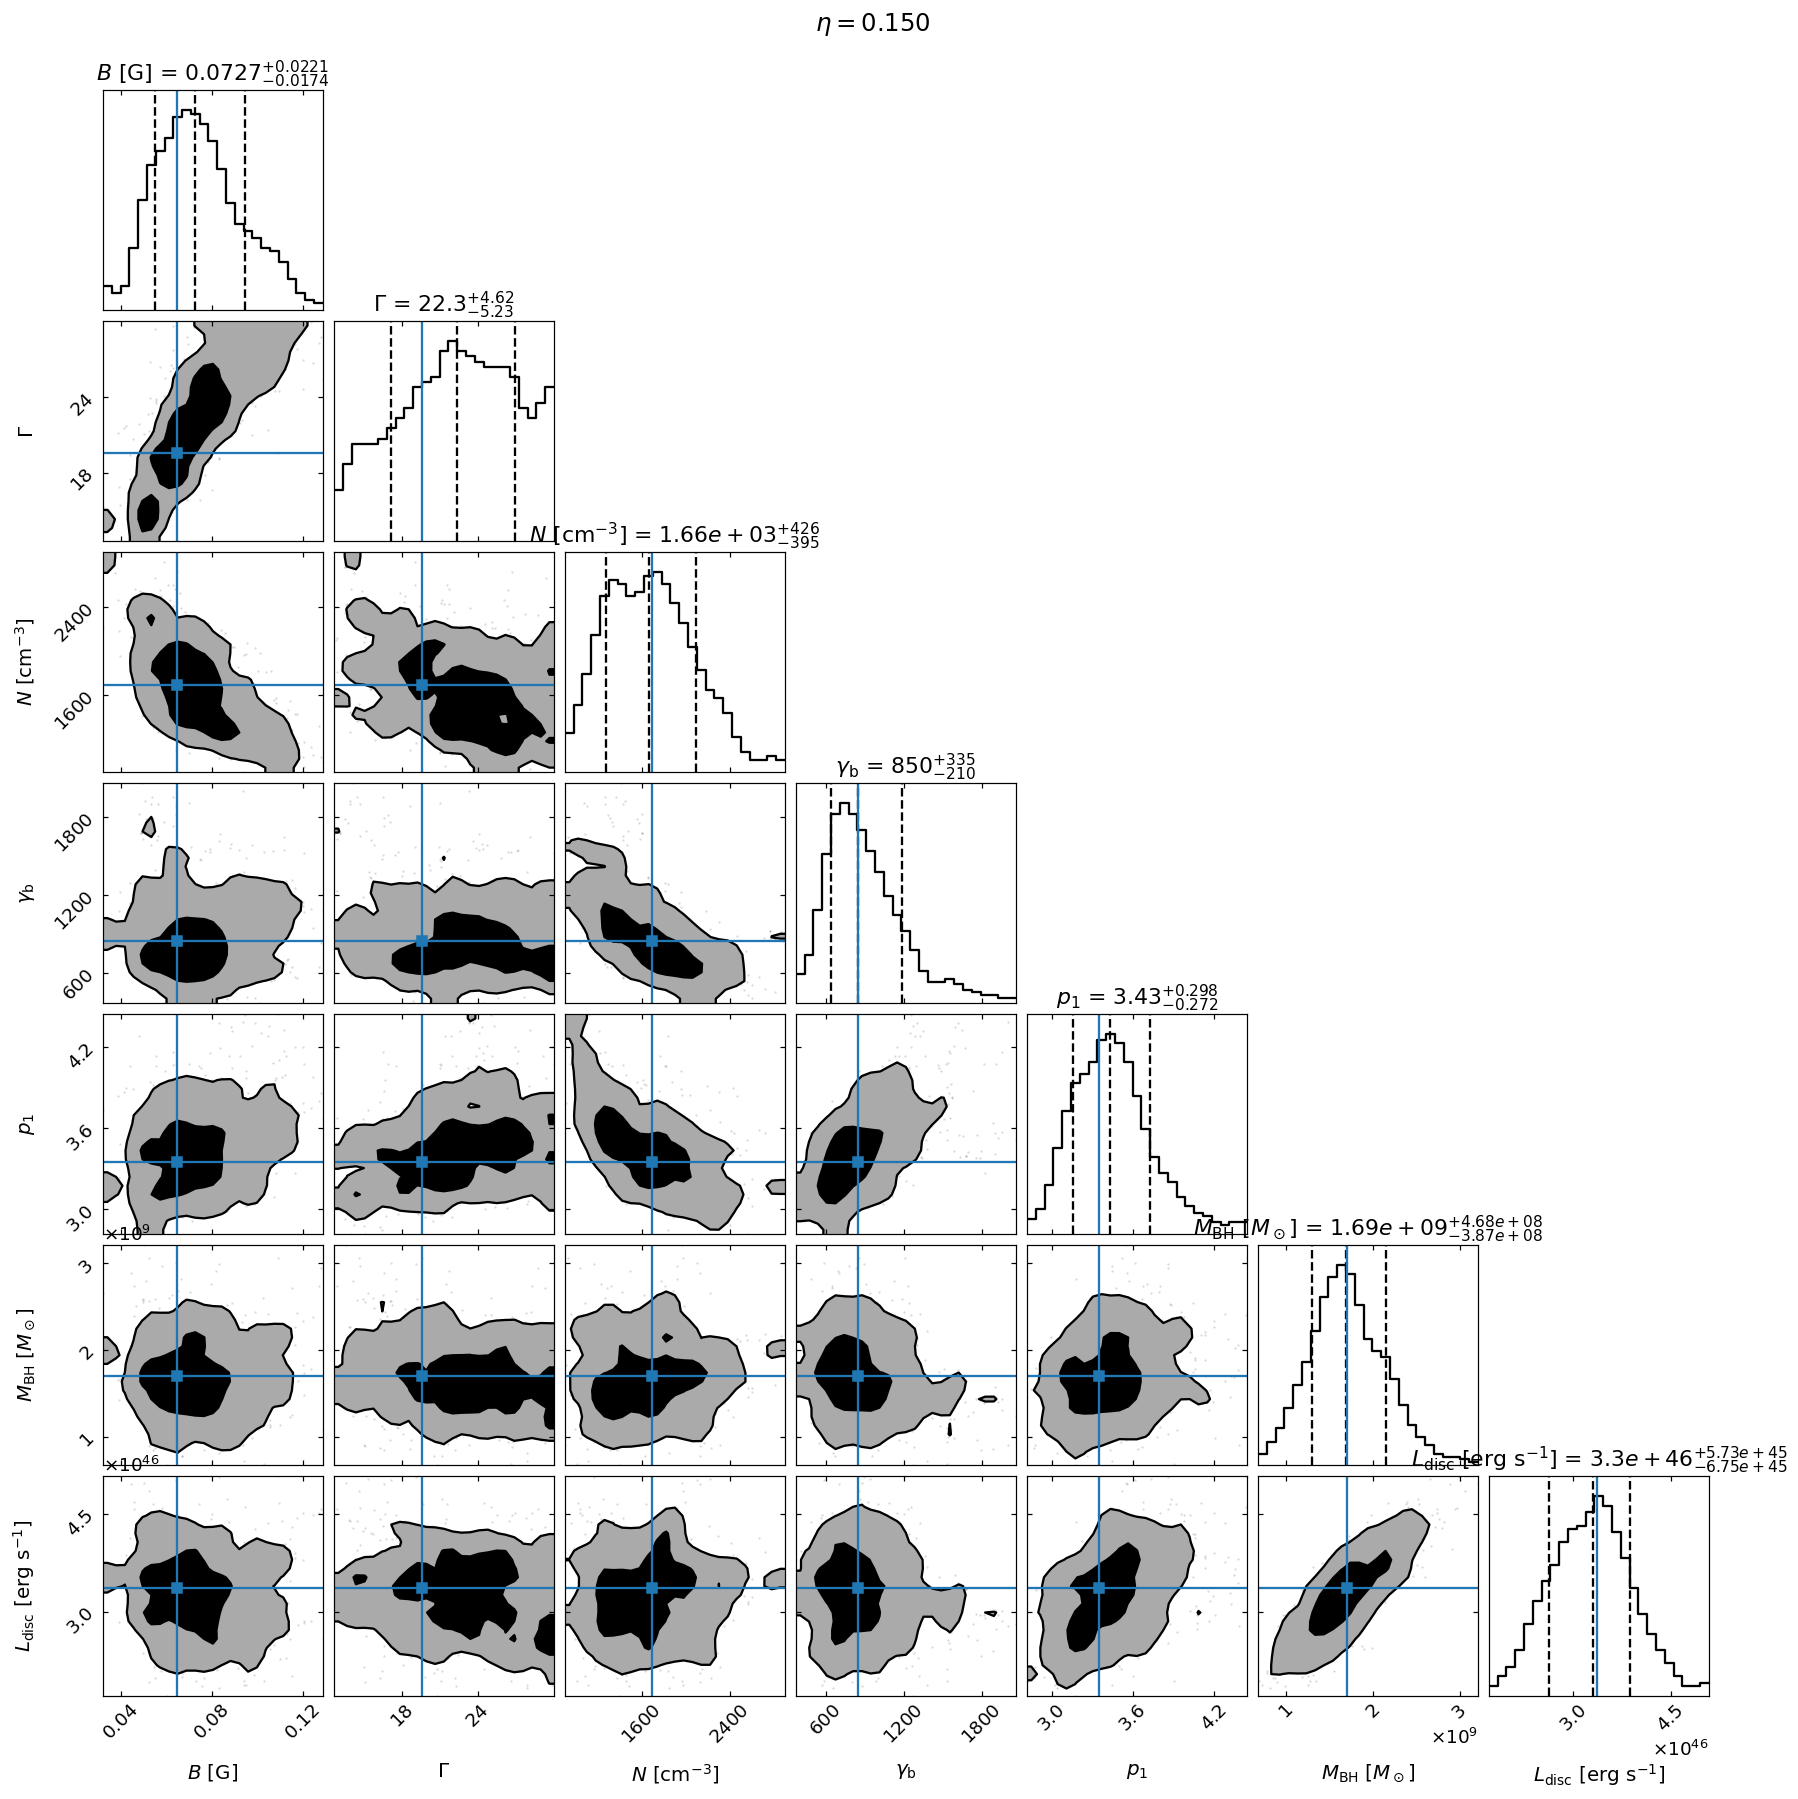


N-B correlation: -0.65
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8

chi2 of the median SED (detections in the fit range): 26.8 for 32 points


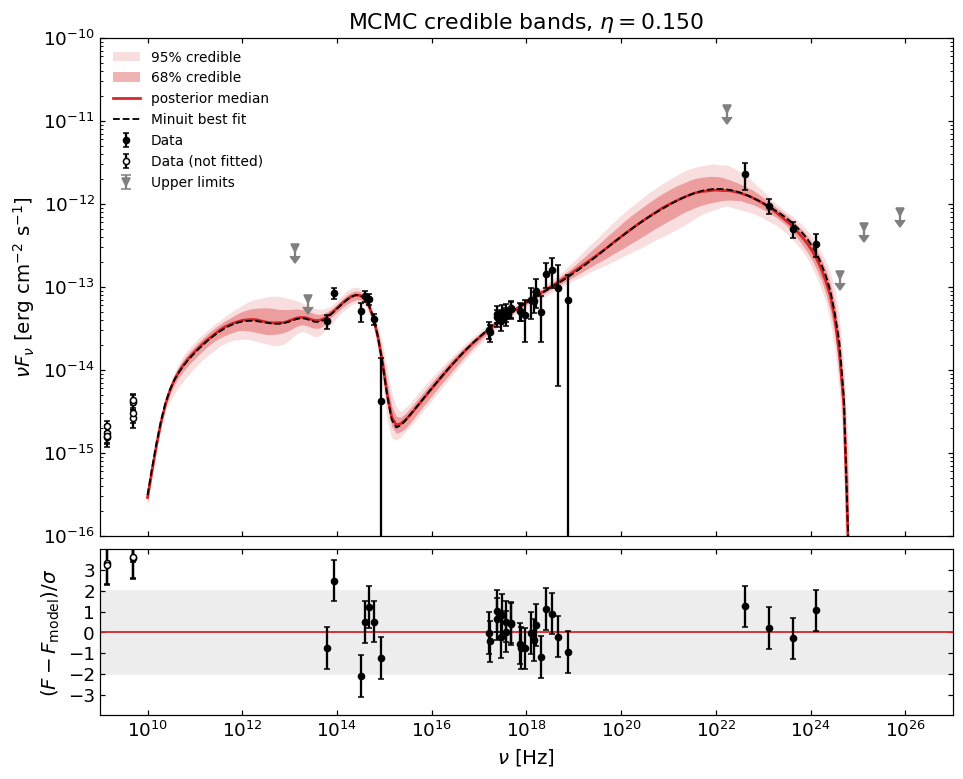

R_H fixed at the Minuit value: 1.158e+18 cm
chain_eta_0p200_7p.npz exists -> sampling skipped

Acceptance fraction: 0.330   (healthy: 0.2-0.5)
   tau(          B) =   46.7 steps   ->   10.7 autocorrelation times
   tau( BulkFactor) =   49.3 steps   ->   10.1 autocorrelation times
   tau(          N) =   49.0 steps   ->   10.2 autocorrelation times
   tau(gamma_break) =   47.7 steps   ->   10.5 autocorrelation times
   tau(        p_1) =   44.0 steps   ->   11.4 autocorrelation times
   tau(       M_BH) =   40.4 steps   ->   12.4 autocorrelation times
   tau(     L_Disk) =   39.7 steps   ->   12.6 autocorrelation times

=== MCMC posterior (eta = 0.200, 7 parameters) ===
  Parameter    Minuit    Median -1 sigma +1 sigma
          B 8.768e-02 9.598e-02 2.42e-02 2.59e-02
 BulkFactor 2.051e+01 2.311e+01 6.17e+00 4.70e+00
          N 1.470e+03 1.454e+03 3.11e+02 4.57e+02
gamma_break 8.053e+02 8.367e+02 2.21e+02 2.93e+02
        p_1 3.560e+00 3.651e+00 3.15e-01 2.99e-01
       M_BH 1.121e+09 

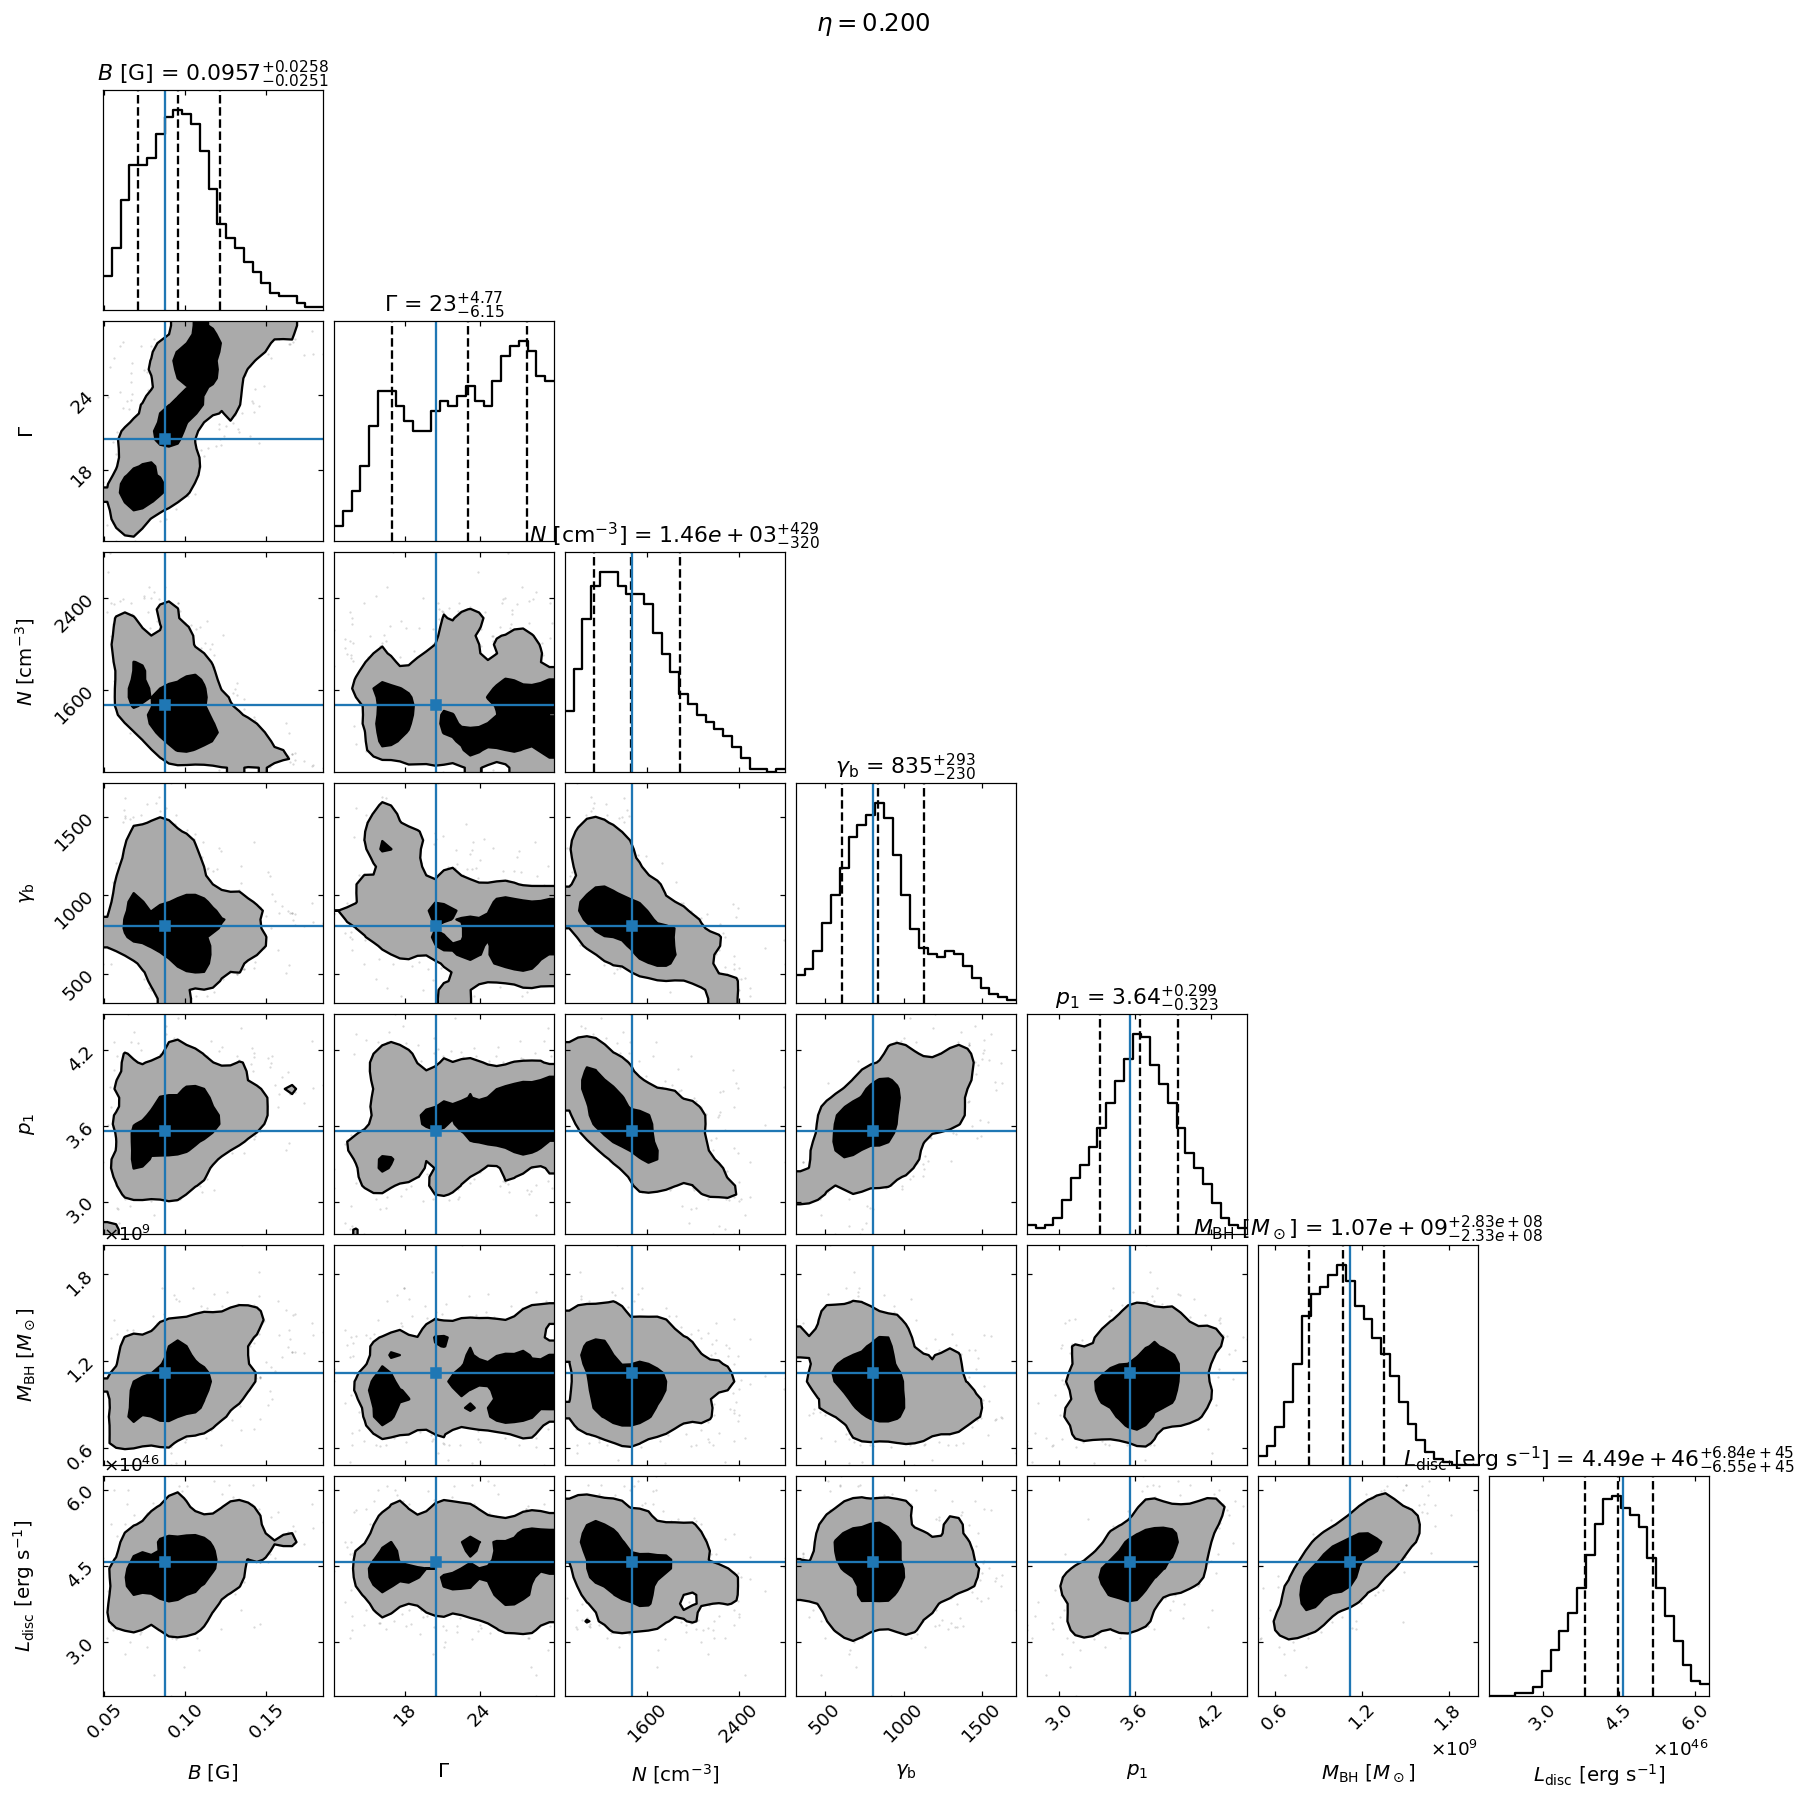


N-B correlation: -0.56
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8

chi2 of the median SED (detections in the fit range): 26.4 for 32 points


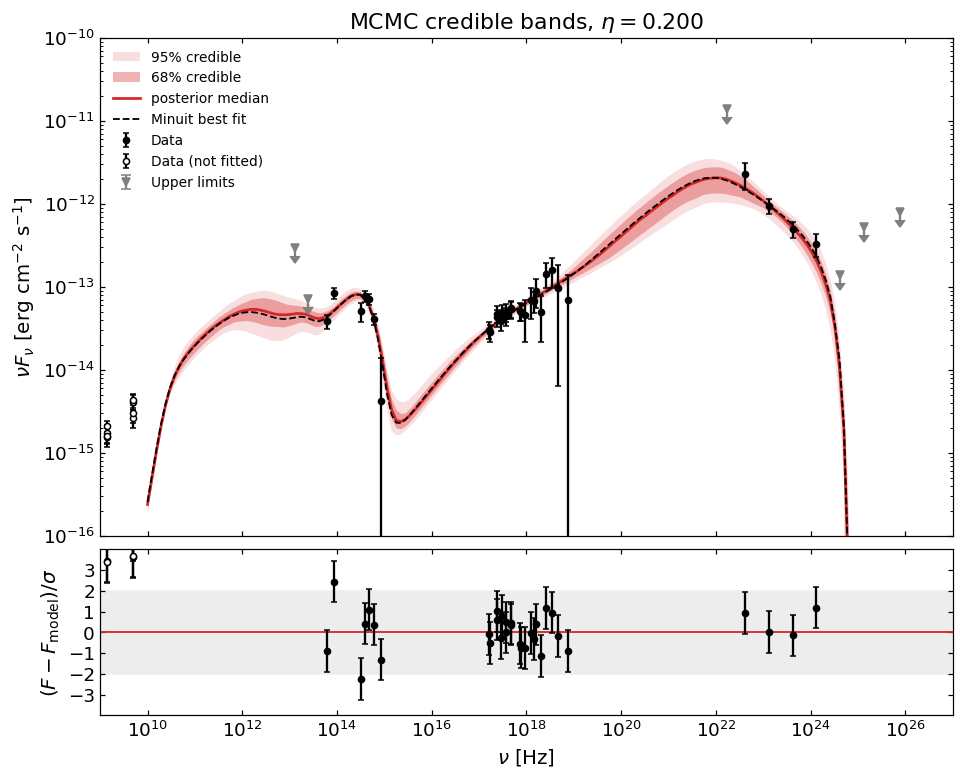

R_H fixed at the Minuit value: 1.417e+18 cm
chain_eta_0p300_7p.npz exists -> sampling skipped

Acceptance fraction: 0.338   (healthy: 0.2-0.5)
   tau(          B) =   48.3 steps   ->   10.3 autocorrelation times
   tau( BulkFactor) =   48.6 steps   ->   10.3 autocorrelation times
   tau(          N) =   47.2 steps   ->   10.6 autocorrelation times
   tau(gamma_break) =   43.4 steps   ->   11.5 autocorrelation times
   tau(        p_1) =   43.5 steps   ->   11.5 autocorrelation times
   tau(       M_BH) =   41.2 steps   ->   12.1 autocorrelation times
   tau(     L_Disk) =   42.7 steps   ->   11.7 autocorrelation times

=== MCMC posterior (eta = 0.300, 7 parameters) ===
  Parameter    Minuit    Median -1 sigma +1 sigma
          B 7.013e-02 7.603e-02 2.02e-02 1.81e-02
 BulkFactor 2.097e+01 2.354e+01 4.76e+00 4.65e+00
          N 1.137e+03 1.202e+03 2.00e+02 4.15e+02
gamma_break 8.543e+02 7.963e+02 2.53e+02 2.91e+02
        p_1 3.492e+00 3.514e+00 2.64e-01 2.74e-01
       M_BH 1.961e+09 

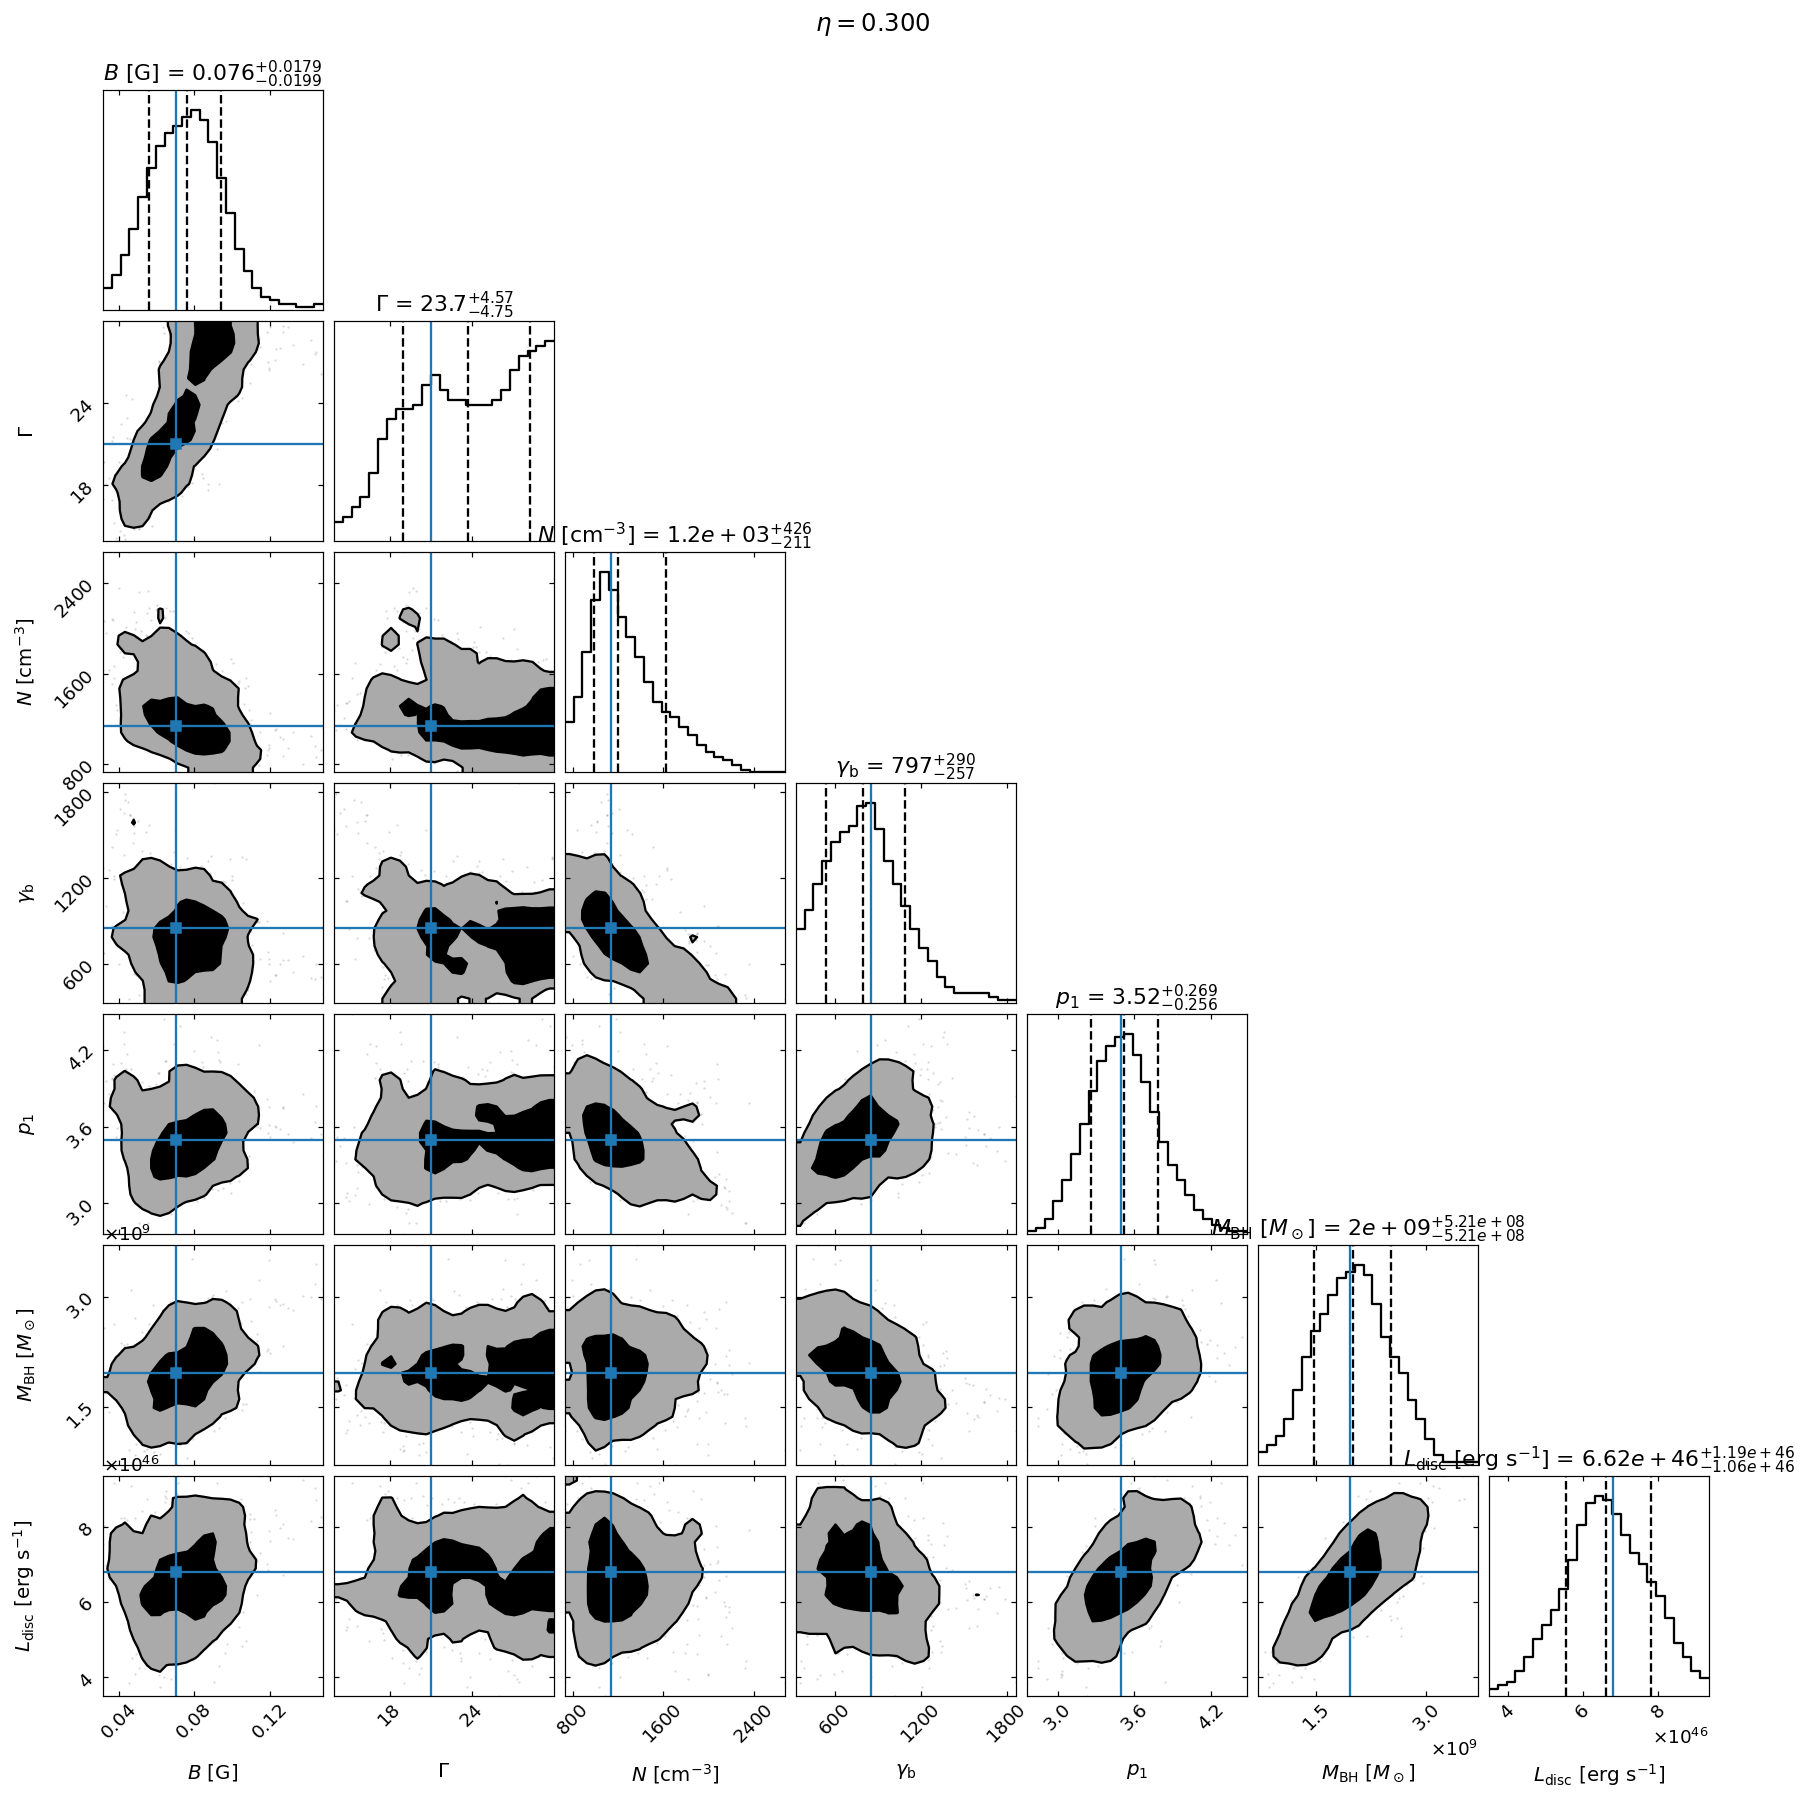


N-B correlation: -0.47
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8

chi2 of the median SED (detections in the fit range): 26.4 for 32 points


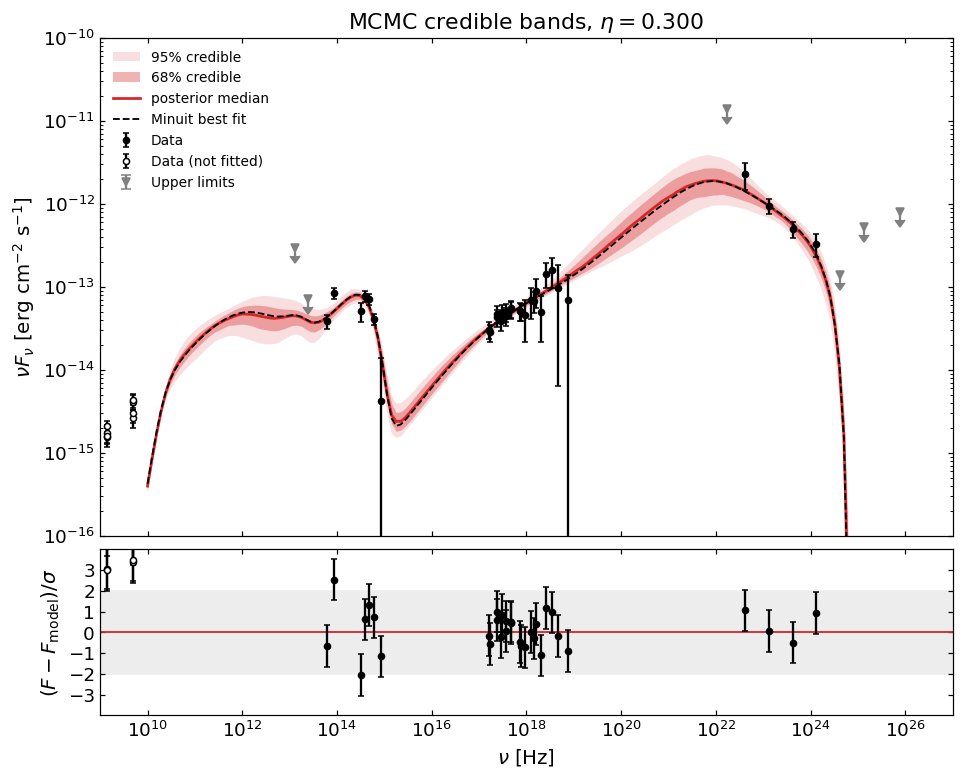

In [5]:
import gc
import corner
from emcee.autocorr import integrated_time

for eta in eta_grid:
    minuit_tag = eta_tag(eta)            # Minuit files (notebook 3)
    tag        = eta_tag(eta) + '_7p'    # files of this MCMC run

    # 1. settings
    sampled_params = ['B', 'BulkFactor', 'N', 'gamma_break', 'p_1',   # jet
                      'M_BH', 'L_Disk']                               # disc
    labels_tex = {'B': r'$B$ [G]', 'BulkFactor': r'$\Gamma$', 'N': r'$N$ [cm$^{-3}$]',
                  'gamma_break': r'$\gamma_{\rm b}$', 'p_1': r'$p_1$',
                  'M_BH': r'$M_{\rm BH}$ [$M_\odot$]', 'L_Disk': r'$L_{\rm disc}$ [erg s$^{-1}$]'}

    nwalkers = 32
    nsteps   = 800
    burnin   = 300

    with open('bounds_eta_grid.json') as f:
        bounds_grid = json.load(f)
    bounds_mcmc = {pname: bounds_grid[pname] for pname in sampled_params}

    # Minuit best fit of this eta (R_H is fixed to it; the rest are reference values)
    with open(f'summary_Minuit_{minuit_tag}.json') as f:
        minuit_par = json.load(f)['params']
    R_H_fixed = minuit_par['R_H']
    print(f"R_H fixed at the Minuit value: {R_H_fixed:.3e} cm")

    # 2. run the sampler (skipped if the chain is already saved)
    if os.path.exists(f'chain_{tag}.npz'):
        print(f"chain_{tag}.npz exists -> sampling skipped")
    else:
        model_minimizer = ModelMinimizer.load_model(f'Minimizer_{minuit_tag}.pkl')

        mcmc = McmcSampler(model_minimizer)
        mcmc.model.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
        mcmc.model.jet_leptonic.set_num_c_threads(8)

        # sanity checks: right eta, R_H at the Minuit value
        eta_in_model = mcmc.model.jet_leptonic.parameters.accr_eff.val
        assert np.isclose(eta_in_model, eta, rtol=1e-3), f"accr_eff = {eta_in_model}, expected {eta}"
        assert np.isclose(mcmc.model.jet_leptonic.parameters.R_H.val, R_H_fixed, rtol=1e-3)

        mcmc.set_labels(use_labels_dict={'jet_leptonic': sampled_params})
        mcmc.set_bounds()                                               # builds the internal list...
        mcmc._bounds = [list(bounds_mcmc[p]) for p in mcmc.labels]      # ...then use our flat-prior box
        print("Sampled:", mcmc.labels)

        mcmc.run_sampler(nwalkers=nwalkers,
                         burnin=burnin,
                         steps=nsteps,
                         walker_start_bound=0.05,
                         progress='notebook')

        # save immediately (plain numpy -> always reloadable)
        np.savez(f'chain_{tag}.npz',
                 samples=mcmc.sampler.get_chain(discard=burnin, flat=True),
                 chain=mcmc.sampler.get_chain(),
                 log_prob=mcmc.sampler.get_log_prob(),
                 labels=np.array(mcmc.labels),
                 burnin=burnin)
        try:
            mcmc.save(f'mcmc_{tag}.pkl')
        except Exception as err:
            print(f"(mcmc.save failed, the npz is saved anyway: {err})")

        del mcmc, model_minimizer
        gc.collect()

    # 3. load the chain
    d = np.load(f'chain_{tag}.npz')
    flat_samples = d['samples']
    chain        = d['chain']
    labels       = list(d['labels'])
    nb           = int(d['burnin'])

    # 4. convergence
    acc = np.any(chain[1:] != chain[:-1], axis=2).mean()      # fraction of steps where a walker moved
    tau = integrated_time(chain[nb:], tol=0)
    print(f"\nAcceptance fraction: {acc:.3f}   (healthy: 0.2-0.5)")
    for pname, t in zip(labels, tau):
        print(f"   tau({pname:>11s}) = {t:6.1f} steps   ->  {(chain.shape[0] - nb) / t:5.1f} autocorrelation times")

    # 5. posterior table + bound check
    #   a parameter is flagged if more than 1% of the samples lie within
    #   1% of the box width from one of its bounds (posterior cut by the prior)
    summary = {'eta': eta, 'tag': tag, 'acceptance': float(acc), 'R_H_fixed': R_H_fixed,
               'n_tau': {p: float((chain.shape[0] - nb) / t) for p, t in zip(labels, tau)},
               'params': {}, 'derived': {}, 'at_bound': []}

    rows = []
    for i, pname in enumerate(labels):
        q16, q50, q84 = np.percentile(flat_samples[:, i], [16, 50, 84])
        summary['params'][pname] = [float(q50), float(q50 - q16), float(q84 - q50)]
        rows.append({'Parameter': pname, 'Minuit': f"{minuit_par[pname]:.3e}", 'Median': f"{q50:.3e}",
                     '-1 sigma': f"{q50 - q16:.2e}", '+1 sigma': f"{q84 - q50:.2e}"})
        lo, hi = bounds_mcmc[pname]
        edge = 0.01 * (hi - lo)
        frac_at_edge = np.mean((flat_samples[:, i] < lo + edge) | (flat_samples[:, i] > hi - edge))
        if frac_at_edge > 0.01:
            summary['at_bound'].append(pname)

    print(f"\n=== MCMC posterior (eta = {eta:.3f}, 7 parameters) ===")
    print(pd.DataFrame(rows).to_string(index=False))
    if summary['at_bound']:
        print("WARNING: posterior cut by the prior bound for", summary['at_bound'])

    # 6. derived quantities
    M_s = flat_samples[:, labels.index('M_BH')]
    L_s = flat_samples[:, labels.index('L_Disk')]

    derived = {
        'lambda':       L_s / (12 * eta) / (1.26e38 * M_s),     # radiated L = L_Disk / (12 eta) in JetSeT MultiBB
        'Mdot_Msun_yr': L_s / (eta * (2.998e10)**2) / 1.989e33 * 3.156e7,
        'R_H/R_BLR':    R_H_fixed / (1.1 * 3e17 * np.sqrt(L_s / 1e46)),
        'R_H/R_DT':     R_H_fixed / (2e19 * np.sqrt(L_s / 1e46)),
    }
    print("\nDerived:")
    for name, arr in derived.items():
        q16, q50, q84 = np.percentile(arr, [16, 50, 84])
        summary['derived'][name] = [float(q50), float(q50 - q16), float(q84 - q50)]
        print(f"   {name:>13s} = {q50:.3e}  -{q50 - q16:.2e} +{q84 - q50:.2e}")

    # 7. corner plot (linear axes, thinned by tau/2, smoothed, 1 and 2 sigma)
    #   blue lines = Minuit best fit
    thin = max(1, int(np.max(tau) / 2))
    samples_thin = chain[nb::thin].reshape(-1, chain.shape[2])
    truths = [minuit_par[p] for p in labels]

    fig = corner.corner(samples_thin, labels=[labels_tex[p] for p in labels],
                        bins=25, smooth=1.0, smooth1d=1.0,
                        levels=(1 - np.exp(-0.5), 1 - np.exp(-2.0)),
                        plot_datapoints=True, data_kwargs={'alpha': 0.15, 'ms': 1.5},
                        fill_contours=True,
                        truths=truths, truth_color='tab:blue',
                        quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g',
                        use_math_text=True, max_n_ticks=3,
                        label_kwargs={'fontsize': 13})
    fig.suptitle(rf'$\eta = {eta:.3f}$', fontsize=16, y=1.02)
    plt.savefig(os.path.join(FIG_DIR, f'corner_MCMC_{tag}.png'), bbox_inches='tight')
    plt.show()

    corr = np.corrcoef(samples_thin.T)
    summary['corr_N_B'] = float(corr[labels.index('N'), labels.index('B')])
    print(f"\nN-B correlation: {summary['corr_N_B']:+.2f}")

    # 8. SED with 68% and 95% credible bands
    #   draw n_draws parameter sets from the posterior, evaluate the model for each,
    #   and take percentiles of nuFnu at every frequency
    n_draws = 300
    rng = np.random.default_rng(42)
    idx = rng.choice(len(flat_samples), size=n_draws, replace=False)

    fit_model = FitModel.load_model(f'Model_Minuit_{minuit_tag}.pkl')
    fit_model.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
    fit_model.jet_leptonic.set_num_c_threads(8)

    # Minuit best fit (reference)
    fit_model.eval()
    nu_grid  = fit_model.SED.nu.value.copy()
    f_minuit = fit_model.SED.nuFnu.value.copy()

    # posterior draws
    seds = np.zeros((n_draws, len(nu_grid)))
    for k, j in enumerate(idx):
        for i, pname in enumerate(labels):
            fit_model.jet_leptonic.parameters.get_par_by_name(pname).val = flat_samples[j, i]
        fit_model.eval()
        seds[k] = np.interp(nu_grid, fit_model.SED.nu.value, fit_model.SED.nuFnu.value)

    f_lo95, f_lo68, f_med, f_hi68, f_hi95 = np.percentile(seds, [2.5, 16, 50, 84, 97.5], axis=0)

    # posterior-median model (all parameters at their median), saved for later parts
    for i, pname in enumerate(labels):
        fit_model.jet_leptonic.parameters.get_par_by_name(pname).val = np.median(flat_samples[:, i])
    fit_model.jet_leptonic.eval()
    fit_model.eval()
    fit_model.save_model(f'Model_MCMC_median_{tag}.pkl')
    np.savez(f'SED_band_{tag}.npz', nu=nu_grid, lo95=f_lo95, lo68=f_lo68, med=f_med,
             hi68=f_hi68, hi95=f_hi95, minuit=f_minuit)

    # 9. residuals of the data with respect to the median SED
    #   (data - model) / sigma, sigma includes the 15% systematic
    nu_d  = np.array(sed_data.table['nu_data'])
    fl_d  = np.array(sed_data.table['nuFnu_data'])
    err_d = np.array(sed_data.table['dnuFnu_data'])
    ul    = np.array(sed_data.table['UL'], dtype=bool)
    in_fit = (nu_d >= NU_FIT_MIN) & (nu_d <= NU_FIT_MAX)

    def model_at(nu, f_model):
        """log-log interpolation of a model SED at the data frequencies"""
        return 10**np.interp(np.log10(nu), np.log10(nu_grid), np.log10(np.clip(f_model, 1e-40, None)))

    f_model_d = model_at(nu_d, f_med)
    resid     = (fl_d - f_model_d) / err_d

    det_fit = (~ul) & in_fit
    chi2_det = np.sum(resid[det_fit]**2)
    print(f"\nchi2 of the median SED (detections in the fit range): {chi2_det:.1f} for {det_fit.sum()} points")
    summary['chi2_median_det'] = float(chi2_det)
    summary['n_det_fit']       = int(det_fit.sum())

    with open(f'summary_MCMC_{tag}.json', 'w') as f:
        json.dump(summary, f, indent=2)

    # 10. SED + residual plot
    fig, (ax, axr) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                                  gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.04})

    ok = f_med > 1e-17
    ax.fill_between(nu_grid[ok], f_lo95[ok], f_hi95[ok], color='tab:red', alpha=0.15, lw=0, label='95% credible')
    ax.fill_between(nu_grid[ok], f_lo68[ok], f_hi68[ok], color='tab:red', alpha=0.35, lw=0, label='68% credible')
    ax.loglog(nu_grid[ok], f_med[ok], color='tab:red', lw=1.8, label='posterior median')
    ax.loglog(nu_grid[ok], f_minuit[ok], color='k', lw=1.2, ls='--', label='Minuit best fit')

    ax.errorbar(nu_d[~ul & in_fit], fl_d[~ul & in_fit], yerr=err_d[~ul & in_fit], fmt='o', color='k',
                ms=4, capsize=2, label='Data', zorder=10)
    ax.errorbar(nu_d[~ul & ~in_fit], fl_d[~ul & ~in_fit], yerr=err_d[~ul & ~in_fit], fmt='o', mfc='white',
                color='k', ms=4, capsize=2, label='Data (not fitted)', zorder=10)
    ax.errorbar(nu_d[ul], fl_d[ul], yerr=0.2 * fl_d[ul], uplims=True, fmt='v', color='gray', ms=5,
                label='Upper limits', zorder=10)

    ax.set_ylim(1e-16, 1e-10)
    ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]')
    ax.set_title(rf'MCMC credible bands, $\eta = {eta:.3f}$')
    ax.legend(fontsize=9, loc='upper left', frameon=False)

    # residual panel: detections only (filled = fitted, open = outside the fit range)
    axr.axhspan(-1, 1, color='0.85', zorder=0)
    axr.axhspan(-2, 2, color='0.93', zorder=0)
    axr.axhline(0, color='tab:red', lw=1.2)
    axr.errorbar(nu_d[det_fit], resid[det_fit], yerr=1, fmt='o', color='k', ms=4, capsize=2)
    axr.errorbar(nu_d[~ul & ~in_fit], resid[~ul & ~in_fit], yerr=1, fmt='o', mfc='white',
                 color='k', ms=4, capsize=2)

    axr.set_xscale('log')
    axr.set_xlim(1e9, 1e27)
    axr.set_ylim(-4, 4)
    axr.set_yticks([-3, -2, -1, 0, 1, 2, 3])
    axr.set_xlabel(r'$\nu$ [Hz]')
    axr.set_ylabel(r'$(F - F_{\rm model}) / \sigma$')

    plt.savefig(os.path.join(FIG_DIR, f'SED_MCMC_band_{tag}.png'), bbox_inches='tight')
    plt.show()

## Posterior trends and MCMC SED overlay

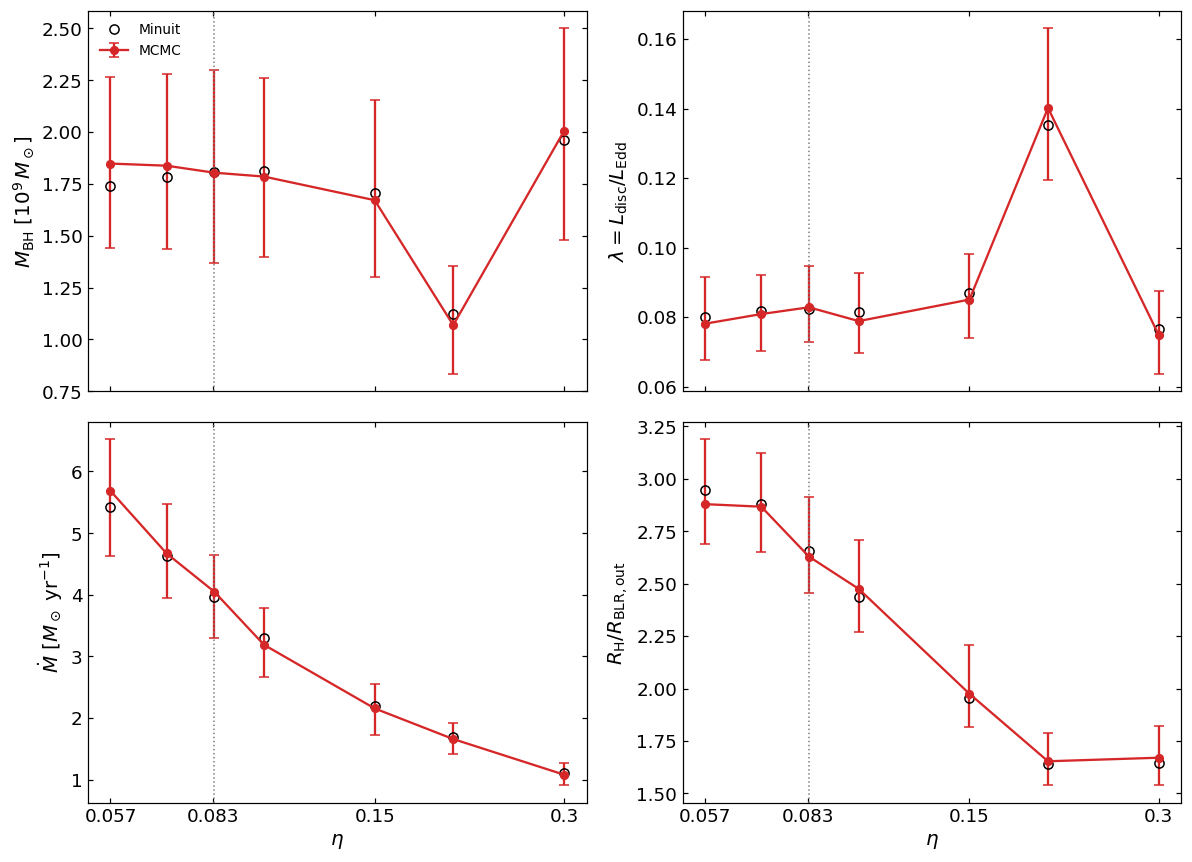

In [6]:
c_cm, M_SUN, YR = 2.998e10, 1.989e33, 3.156e7

mc, mn = {}, {}
for eta in eta_grid:
    tag = eta_tag(eta)
    with open(f'summary_MCMC_{tag}_7p.json') as f:
        mc[eta] = json.load(f)
    with open(f'summary_Minuit_{tag}.json') as f:
        mn[eta] = json.load(f)
etas = list(mc.keys())

def minuit_value(eta, key):
    par = mn[eta]['params']
    L_disc = par['L_Disk'] / (12 * eta)
    if key == 'lambda':
        return L_disc / (1.26e38 * par['M_BH'])
    if key == 'Mdot_phys':
        return L_disc / (eta * c_cm**2) / M_SUN * YR
    if key == 'R_H/R_BLR':
        return par['R_H'] / mn[eta]['R_BLR_out']
    if key == 'M_BH':
        return par['M_BH'] / 1e9

def mcmc_value(eta, key):
    """median, -err, +err"""
    if key == 'M_BH':
        return [v / 1e9 for v in mc[eta]['params']['M_BH']]
    if key == 'Mdot_phys':
        return [v / (12 * eta) for v in mc[eta]['derived']['Mdot_Msun_yr']]
    return mc[eta]['derived'][key]

panels = [('M_BH',      r'$M_{\rm BH}$ [$10^9\,M_\odot$]'),
          ('lambda',    r'$\lambda = L_{\rm disc}/L_{\rm Edd}$'),
          ('Mdot_phys', r'$\dot M$ [$M_\odot$ yr$^{-1}$]'),
          ('R_H/R_BLR', r'$R_{\rm H}/R_{\rm BLR,out}$')]

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax, (key, lab) in zip(axes.ravel(), panels):
    vals = np.array([mcmc_value(e, key) for e in etas])
    ax.errorbar(etas, vals[:, 0], yerr=[vals[:, 1], vals[:, 2]], fmt='o-', color='tab:red',
                ms=5, capsize=3, label='MCMC')
    ax.plot(etas, [minuit_value(e, key) for e in etas], 'o', mfc='none', color='k', ms=6,
            label='Minuit')
    ax.axvline(1/12, color='gray', ls=':', lw=1)
    ax.set_ylabel(lab)
    ax.set_xscale('log')
    ax.set_xticks([0.057, 0.083, 0.15, 0.3])
    ax.set_xticklabels(['0.057', '0.083', '0.15', '0.3'])
    ax.minorticks_off()
for ax in axes[-1]:
    ax.set_xlabel(r'$\eta$')
axes[0, 0].legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eta_grid_mcmc_trends.png'), bbox_inches='tight')
plt.show()

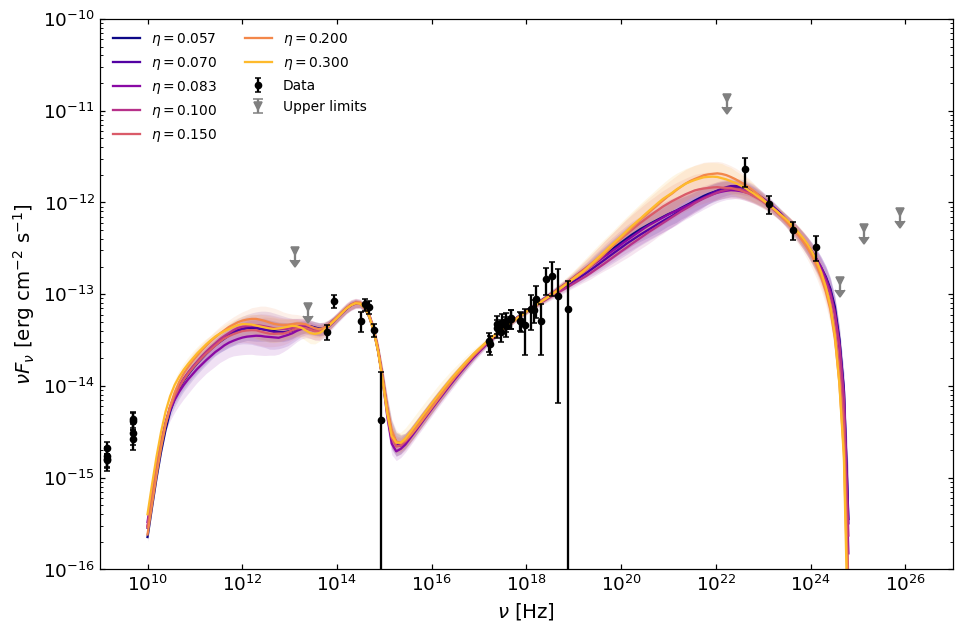

In [7]:
# overlay of the MCMC SEDs (median + 68% band), no title
colors = plt.cm.plasma(np.linspace(0.0, 0.85, len(etas)))
fig, ax = plt.subplots(figsize=(10, 6.5))
for eta, col in zip(etas, colors):
    b = np.load(f'SED_band_{eta_tag(eta)}_7p.npz')
    ok = b['med'] > 1e-17
    ax.fill_between(b['nu'][ok], b['lo68'][ok], b['hi68'][ok], color=col, alpha=0.12, lw=0)
    ax.loglog(b['nu'][ok], b['med'][ok], color=col, lw=1.5, label=rf'$\eta = {eta:.3f}$')

nu_d  = np.array(sed_data.table['nu_data'])
fl_d  = np.array(sed_data.table['nuFnu_data'])
err_d = np.array(sed_data.table['dnuFnu_data'])
ul    = np.array(sed_data.table['UL'], dtype=bool)
ax.errorbar(nu_d[~ul], fl_d[~ul], yerr=err_d[~ul], fmt='o', color='k', ms=4, capsize=2,
            label='Data', zorder=10)
ax.errorbar(nu_d[ul], fl_d[ul], yerr=0.2 * fl_d[ul], uplims=True, fmt='v', color='gray', ms=5,
            label='Upper limits', zorder=10)

ax.set_xlim(1e9, 1e27)
ax.set_ylim(1e-16, 1e-10)
ax.set_xlabel(r'$\nu$ [Hz]')
ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]')
ax.legend(fontsize=9, ncol=2, loc='upper left', frameon=False)
plt.savefig(os.path.join(FIG_DIR, 'SED_MCMC_eta_overlay.png'), bbox_inches='tight')
plt.show()

## Minuit SEDs without titles (versions used in the thesis)

In [8]:
plot_tags = ['base_eta0p083'] + [eta_tag(eta) for eta in eta_grid]

for tag in plot_tags:
    fm = FitModel.load_model(f'Model_Minuit_{tag}.pkl')
    fm.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
    fm.jet_leptonic.eval()
    fm.eval()

    p = fm.plot_model(sed_data=sed_data)
    p.setlim(y_min=1e-16, x_min=1e8)
    plt.savefig(os.path.join(FIG_DIR, f'SED_Minuit_{tag}.png'), bbox_inches='tight')
    plt.close('all')
    print('saved', f'SED_Minuit_{tag}.png')

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
saved SED_Minuit_base_eta0p083.png
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] accord